# Hidden states & active neurons vs. forgetting
### `15shot_trajectory_top10_internal_with_hidden`

This dataset is the first one that ships the **raw hidden states** for every fact at
every checkpoint (the earlier `--no-hidden` runs only kept scalar readouts). For each
of the 13 checkpoints we have, for **1452 facts**:

- `hidden_step{S}_answer.npy` &nbsp;— `(1452, 19, 2048)` float16, residual stream at the
  **answer** token across the 19 layer boundaries (embeddings + 18 blocks).
- `hidden_step{S}_subject_last.npy` — same, at the **last subject** token.
- `hidden_step{S}_ids.npy` — the 1452 fact ids (identical order at every checkpoint,
  and identical to the recall parquet order).
- `recall_step{S}_15shot_top10pct.parquet` — 34-column readout table incl.
  `correct`, `gold_prob`, and the **active-neuron** stats (`mlp_active_frac_by_layer`,
  `mlp_participation_by_layer`, …) for both positions.

**Question.** When a fact is *about to be forgotten* (correct now, wrong at the next
checkpoint), is that already legible in its internal representation — its geometry
(drift, position relative to the "correct" manifold, layer of resolution) and its
MLP activity (how many neurons fire)?

*Forgetting event* = a fact `correct` at checkpoint `t` and **not** `correct` at `t+1`.

In [1]:
import glob, re, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# --- visual style (matches the other project notebooks) ---
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
BLUE, ORANGE, RED, NEUTRAL = "#2a78d6", "#eb6834", "#e34948", "#f0efec"
plt.rcParams.update({
    "figure.dpi": 130,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "text.color": INK, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRID, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "legend.frameon": False,
})
C_SURV, C_FORG = BLUE, ORANGE          # will-survive vs will-forget
pct = lambda v, _: f"{v:.0%}"

BASE = "data/artifacts/expermints/15shot_trajectory_top10_internal_with_hidden"
INT, REC = f"{BASE}/internal", f"{BASE}/recall"

# The files carry browser-download suffixes like " (1)"/" (2)"; index them by step.
def index_by_step(pattern):
    out = {}
    for f in glob.glob(pattern):
        m = re.search(r"step(\d+)", os.path.basename(f))
        if m: out[int(m.group(1))] = f
    return out

rec_files = index_by_step(f"{REC}/*.parquet")
ans_files = index_by_step(f"{INT}/hidden_step*_answer*.npy")
subj_files = index_by_step(f"{INT}/hidden_step*_subject_last*.npy")
id_files  = index_by_step(f"{INT}/hidden_step*_ids*.npy")
STEPS = sorted(rec_files)
print("checkpoints:", STEPS)
assert set(STEPS) == set(ans_files) == set(subj_files) == set(id_files)

checkpoints: [50000, 100000, 150000, 200000, 250000, 300000, 350000, 400000, 450000, 500000, 550000, 600000, 658032]


In [2]:
# ---- recall tables -> correctness matrix + scalar/active-neuron features ----
IDS = np.load(id_files[STEPS[0]])                    # canonical fact order
for s in STEPS:                                      # order is identical everywhere
    assert (np.load(id_files[s]) == IDS).all()
n_facts, n_steps = len(IDS), len(STEPS)

recall = {s: pd.read_parquet(rec_files[s]) for s in STEPS}
for s in STEPS:
    assert (recall[s]["id"].to_numpy() == IDS).all()

correct  = np.column_stack([recall[s]["correct"].to_numpy().astype(bool) for s in STEPS])
excluded = recall[STEPS[0]]["excluded"].to_numpy().astype(bool)   # a fact-level property
scoreable = ~excluded

def feat_matrix(col):
    # returned as (n_steps, n_facts) to match rep_margin / drift indexing
    return np.column_stack([pd.to_numeric(recall[s][col], errors="coerce").to_numpy()
                            for s in STEPS]).astype(float).T
gold_prob = feat_matrix("gold_prob")
answer_margin = feat_matrix("answer_margin")

# fact metadata (relation, co-occurrence, precomputed forgetting counts)
fp = pd.read_csv("15_shot_top_10_trajectory_with_fact_properites.csv").set_index("id").loc[IDS]

print(f"{n_facts} facts x {n_steps} checkpoints | {scoreable.sum()} scoreable "
      f"({excluded.sum()} excluded)")
print("mean recall by checkpoint:",
      np.round(correct[scoreable].mean(0), 3))

1452 facts x 13 checkpoints | 1310 scoreable (142 excluded)
mean recall by checkpoint: [0.147 0.179 0.26  0.227 0.228 0.185 0.286 0.29  0.28  0.351 0.38  0.363
 0.415]


In [3]:
# ---- forgetting bookkeeping (all restricted to scoreable facts) ----
# For every (fact, t) that is correct at t and observed at t+1, label whether it is
# forgotten at t+1.  These aligned masks drive the survive/forget comparisons.
def transition_masks():
    cur, forget, t_idx, fact_idx = [], [], [], []
    for t in range(n_steps - 1):
        m = scoreable & correct[:, t]
        idx = np.where(m)[0]
        cur.append(idx)
        forget.append(~correct[idx, t + 1])
        t_idx.append(np.full(idx.size, t))
        fact_idx.append(idx)
    return (np.concatenate(fact_idx), np.concatenate(t_idx),
            np.concatenate(forget).astype(bool))

TR_FACT, TR_T, TR_FORGET = transition_masks()
print(f"correct->next transitions: {TR_FORGET.size}  "
      f"(forgotten next: {TR_FORGET.mean():.1%})")

correct->next transitions: 4163  (forgotten next: 24.2%)


## Loading the hidden states

The full tensors are ~113 MB each (26 files, ~3 GB). We stream one checkpoint at a
time and keep only what the analyses need:

- **final-layer** residual (layer index 18) at both positions, for every fact/checkpoint
  → the "read-out" representation used for drift and the correctness manifold;
- a per-checkpoint, **per-layer separability** grid (how linearly `correct` sits in the
  residual stream at each depth) computed on the fly so the big tensors never co-reside.

In [4]:
L_FINAL = 18            # 19 layer-boundaries: 0=embeddings ... 18=final residual

Hf_ans  = np.empty((n_steps, n_facts, 2048), np.float32)   # final-layer, answer pos
Hf_subj = np.empty((n_steps, n_facts, 2048), np.float32)   # final-layer, subject pos

def nc_auc(X, y):
    # in-sample nearest-centroid separability: AUC of (d_wrong - d_correct) for y
    if y.sum() < 5 or (~y).sum() < 5:
        return np.nan
    mu_c, mu_w = X[y].mean(0), X[~y].mean(0)
    score = np.linalg.norm(X - mu_w, axis=1) - np.linalg.norm(X - mu_c, axis=1)
    # AUC via Mann-Whitney U on the score
    order = np.argsort(score); ranks = np.empty_like(order, float)
    ranks[order] = np.arange(1, len(score) + 1)
    r_pos = ranks[y].sum(); n1, n0 = y.sum(), (~y).sum()
    return (r_pos - n1 * (n1 + 1) / 2) / (n1 * n0)

sep_by_layer = np.full((n_steps, 19), np.nan)     # answer-pos correctness separability

for ti, s in enumerate(STEPS):
    A = np.load(ans_files[s]).astype(np.float32)      # (n_facts, 19, 2048)
    S = np.load(subj_files[s]).astype(np.float32)
    Hf_ans[ti]  = A[:, L_FINAL, :]
    Hf_subj[ti] = S[:, L_FINAL, :]
    y = correct[:, ti][scoreable]
    for L in range(19):
        sep_by_layer[ti, L] = nc_auc(A[scoreable, L, :], y)
    del A, S
print("loaded final-layer residuals:", Hf_ans.shape,
      "| separability grid:", sep_by_layer.shape)

loaded final-layer residuals: (13, 1452, 2048) | separability grid: (13, 19)


## 1 · Recall trajectory and where correctness lives in the stream

Left: the familiar non-monotonic climb in recall (the wobble is what makes
"forgetting" a real, recurring event and not just a warm-up artefact). Right: how
**linearly separable** correct vs. incorrect facts are in the residual stream at each
layer — averaged over checkpoints, for both token positions. This locates the depth at
which "do I know this fact" becomes legible.

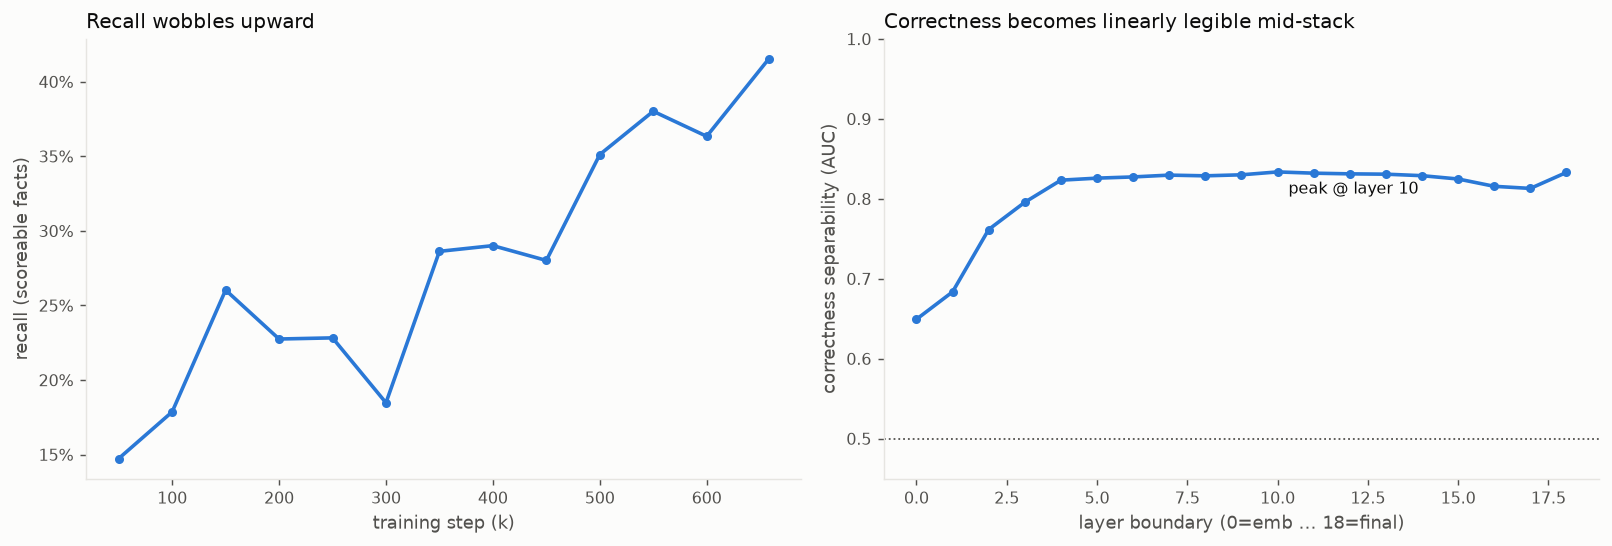

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
xk = [s / 1000 for s in STEPS]

ax1.plot(xk, correct[scoreable].mean(0), color=BLUE, lw=2, marker="o", ms=4)
ax1.yaxis.set_major_formatter(FuncFormatter(pct))
ax1.set_xlabel("training step (k)"); ax1.set_ylabel("recall (scoreable facts)")
ax1.set_title("Recall wobbles upward", loc="left")

ax2.plot(range(19), np.nanmean(sep_by_layer, 0), color=BLUE, lw=2, marker="o", ms=4,
         label="answer position")
# subject-position separability (compute quickly from stored final only? -> recompute)
ax2.axhline(0.5, color=INK2, lw=1, ls=":")
ax2.set_xlabel("layer boundary (0=emb … 18=final)")
ax2.set_ylabel("correctness separability (AUC)")
ax2.set_title("Correctness becomes linearly legible mid-stack", loc="left")
ax2.set_ylim(0.45, 1.0)
peak = int(np.nanargmax(np.nanmean(sep_by_layer, 0)))
ax2.annotate(f"peak @ layer {peak}", (peak, np.nanmean(sep_by_layer,0)[peak]),
             textcoords="offset points", xytext=(6, -12), color=INK, fontsize=9)
plt.tight_layout(); plt.show()

## 2 · Representational drift: do soon-to-be-forgotten facts move more?

For each fact we measure step-to-step **drift** of its final-layer answer
representation, `drift_{t→t+1} = 1 − cos(h_t, h_{t+1})`. Among facts that are correct at
`t`, we split by whether they are forgotten at `t+1`.

If forgetting is a representation being *dislodged*, the forgotten group should drift
more across the very transition where they flip.

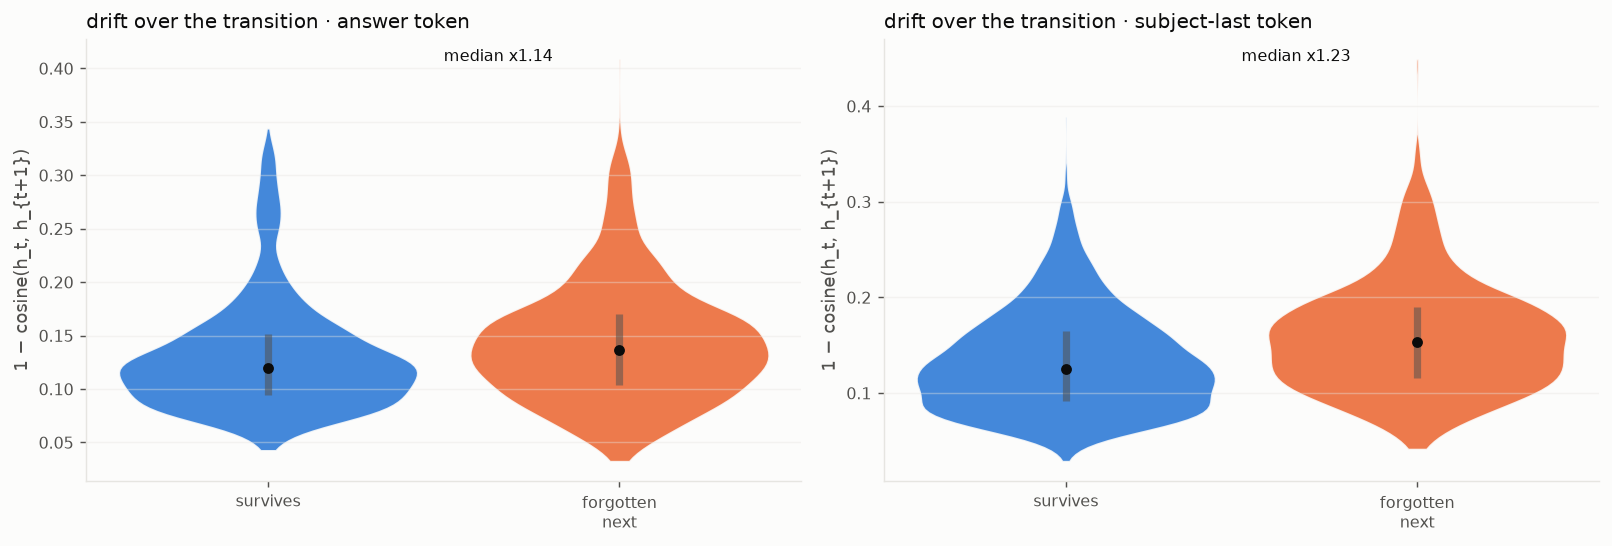

answer: median drift forget=0.137 vs survive=0.120  (MWU p=1.9e-16)
subject: median drift forget=0.153 vs survive=0.125  (MWU p=5.1e-37)


In [6]:
def cos_drift(H):
    # (n_steps-1, n_facts) cosine drift between consecutive checkpoints
    Hn = H / (np.linalg.norm(H, axis=2, keepdims=True) + 1e-8)
    return 1.0 - np.einsum("tfd,tfd->tf", Hn[:-1], Hn[1:])

drift_ans  = cos_drift(Hf_ans)      # (n_steps-1, n_facts)
drift_subj = cos_drift(Hf_subj)

# align to the correct->next transitions
d_ans  = drift_ans[TR_T, TR_FACT]
d_subj = drift_subj[TR_T, TR_FACT]

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))
for ax, d, name in zip(axes, [d_ans, d_subj], ["answer token", "subject-last token"]):
    surv, forg = d[~TR_FORGET], d[TR_FORGET]
    parts = ax.violinplot([surv, forg], positions=[1, 2], widths=0.85, showextrema=False)
    for body, col in zip(parts["bodies"], (C_SURV, C_FORG)):
        body.set_facecolor(col); body.set_edgecolor(SURF); body.set_alpha(.88)
    for pos, dd in zip((1, 2), (surv, forg)):
        q1, me, q3 = np.percentile(dd, [25, 50, 75])
        ax.vlines(pos, q1, q3, color=INK2, lw=4, alpha=.55); ax.plot(pos, me, "o", color=INK, ms=5)
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"])
    ax.set_title(f"drift over the transition · {name}", loc="left")
    ax.set_ylabel("1 − cosine(h_t, h_{t+1})"); ax.grid(axis="y", alpha=.4)
    ax.annotate(f"median x{np.median(forg)/np.median(surv):.2f}", (0.5, 0.95),
                xycoords="axes fraction", color=INK, fontsize=9)
plt.tight_layout(); plt.show()

from scipy.stats import mannwhitneyu
for d, name in [(d_ans, "answer"), (d_subj, "subject")]:
    u, p = mannwhitneyu(d[TR_FORGET], d[~TR_FORGET], alternative="greater")
    print(f"{name}: median drift forget={np.median(d[TR_FORGET]):.3f} "
          f"vs survive={np.median(d[~TR_FORGET]):.3f}  (MWU p={p:.1e})")

## 3 · Position relative to the "correct" manifold

Drift says *how much* a representation moves; this asks *where it sits*. At each
checkpoint we take the centroid of the final-layer answer reps of correct vs. incorrect
scoreable facts and define a **representational margin**

`rep_margin = ‖h − μ_wrong‖ − ‖h − μ_correct‖`  (positive ⇒ closer to the correct manifold).

Among facts that are currently correct, is a *smaller* margin — sitting near the
decision boundary — a leading indicator of being forgotten next step?

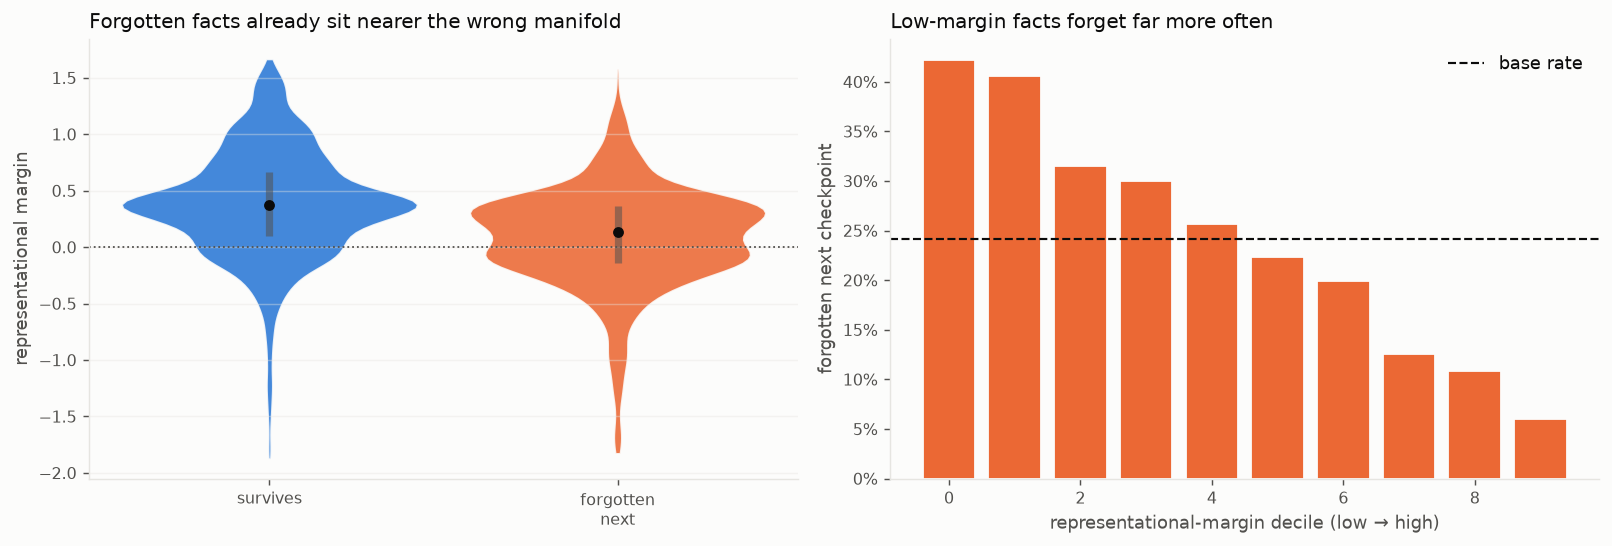

In [7]:
rep_margin = np.full((n_steps, n_facts), np.nan)
for ti in range(n_steps):
    y = correct[:, ti] & scoreable
    w = (~correct[:, ti]) & scoreable
    mu_c, mu_w = Hf_ans[ti][y].mean(0), Hf_ans[ti][w].mean(0)
    rep_margin[ti] = (np.linalg.norm(Hf_ans[ti] - mu_w, axis=1)
                      - np.linalg.norm(Hf_ans[ti] - mu_c, axis=1))

m_tr = rep_margin[TR_T, TR_FACT]
surv, forg = m_tr[~TR_FORGET], m_tr[TR_FORGET]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
parts = ax1.violinplot([surv, forg], positions=[1, 2], widths=0.85, showextrema=False)
for body, col in zip(parts["bodies"], (C_SURV, C_FORG)):
    body.set_facecolor(col); body.set_edgecolor(SURF); body.set_alpha(.88)
for pos, dd in zip((1, 2), (surv, forg)):
    q1, me, q3 = np.percentile(dd, [25, 50, 75])
    ax1.vlines(pos, q1, q3, color=INK2, lw=4, alpha=.55); ax1.plot(pos, me, "o", color=INK, ms=5)
ax1.axhline(0, color=INK2, lw=1, ls=":")
ax1.set_xticks([1, 2], ["survives", "forgotten\nnext"])
ax1.set_ylabel("representational margin"); ax1.grid(axis="y", alpha=.4)
ax1.set_title("Forgotten facts already sit nearer the wrong manifold", loc="left")

# decile view: forgetting rate vs current representational margin
q = pd.qcut(m_tr, 10, labels=False, duplicates="drop")
rate = [TR_FORGET[q == i].mean() for i in range(q.max() + 1)]
ax2.bar(range(len(rate)), rate, color=ORANGE, edgecolor=SURF)
ax2.axhline(TR_FORGET.mean(), color=INK, ls="--", lw=1.2, label="base rate")
ax2.yaxis.set_major_formatter(FuncFormatter(pct))
ax2.set_xlabel("representational-margin decile (low → high)")
ax2.set_ylabel("forgotten next checkpoint"); ax2.legend()
ax2.set_title("Low-margin facts forget far more often", loc="left")
plt.tight_layout(); plt.show()

## 4 · Event-centered internals around the moment of forgetting

Aligning each forgetting event at τ=0 (last checkpoint still correct; τ=+1 first wrong)
and taking medians across events shows the *shape* of the collapse — abrupt cliff vs.
slow slide — for the representational margin, its drift, and the scalar `gold_prob`
read-out for reference.

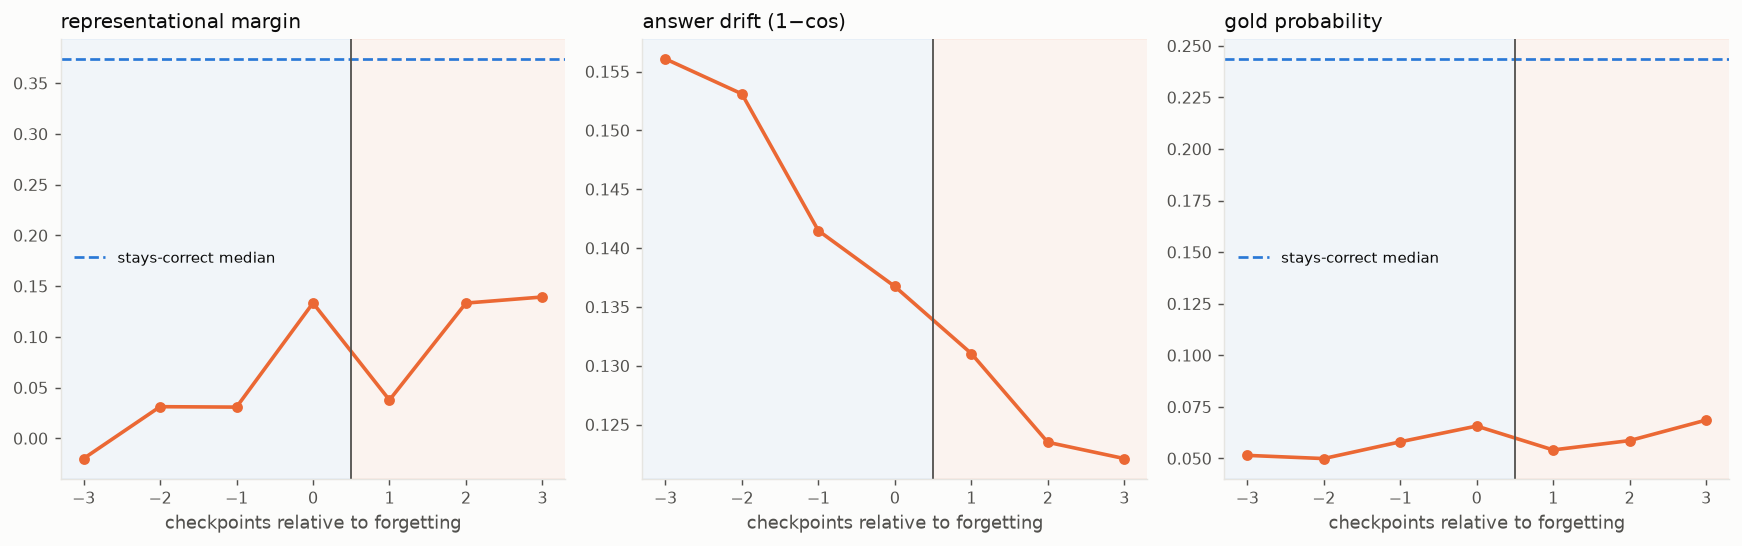

In [8]:
offsets = range(-3, 4)
def event_curve(M, kind="value"):
    out = []
    for tau in offsets:
        vals = []
        for t in range(n_steps - 1):
            ev = scoreable & correct[:, t] & (~correct[:, t + 1])
            j = t + tau
            if kind == "value" and 0 <= j < n_steps:
                vals.append(M[j, ev] if M.shape[0] == n_steps else M[ev, j])
            elif kind == "drift" and 0 <= j < M.shape[0]:
                vals.append(M[j, ev])
        out.append(np.nanmedian(np.concatenate(vals)) if vals else np.nan)
    return np.array(out)

curves = [(rep_margin, "value", "representational margin", False),
          (drift_ans,  "drift", "answer drift (1−cos)",    False),
          (gold_prob,  "value", "gold probability",        False)]
surv_ref = {"representational margin": np.nanmedian(m_tr[~TR_FORGET]),
            "gold probability": np.nanmedian(gold_prob[TR_T, TR_FACT][~TR_FORGET])}

xo = list(offsets)
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for ax, (M, kind, label, log) in zip(axes, curves):
    y = event_curve(M, kind)
    ax.axvspan(-3.5, 0.5, color=BLUE, alpha=.05); ax.axvspan(0.5, 3.5, color=ORANGE, alpha=.06)
    ax.plot(xo, y, color=C_FORG, lw=2, marker="o", ms=5)
    if label in surv_ref:
        ax.axhline(surv_ref[label], color=C_SURV, ls="--", lw=1.5, label="stays-correct median")
        ax.legend(loc="best", fontsize=8.5)
    ax.axvline(0.5, color=INK2, lw=1)
    ax.set_xlim(-3.3, 3.3); ax.set_xlabel("checkpoints relative to forgetting")
    ax.set_title(label, loc="left")
plt.tight_layout(); plt.show()

## 5 · Active neurons: how much of the MLP fires?

The recall tables carry, per layer, the **fraction of MLP hidden units that activate**
(`mlp_active_frac_by_layer`) and their **participation** (effective number of units
carrying the L1 mass) at both positions. We ask whether soon-to-be-forgotten facts
under-use the MLP — a sparser, less-committed computation.

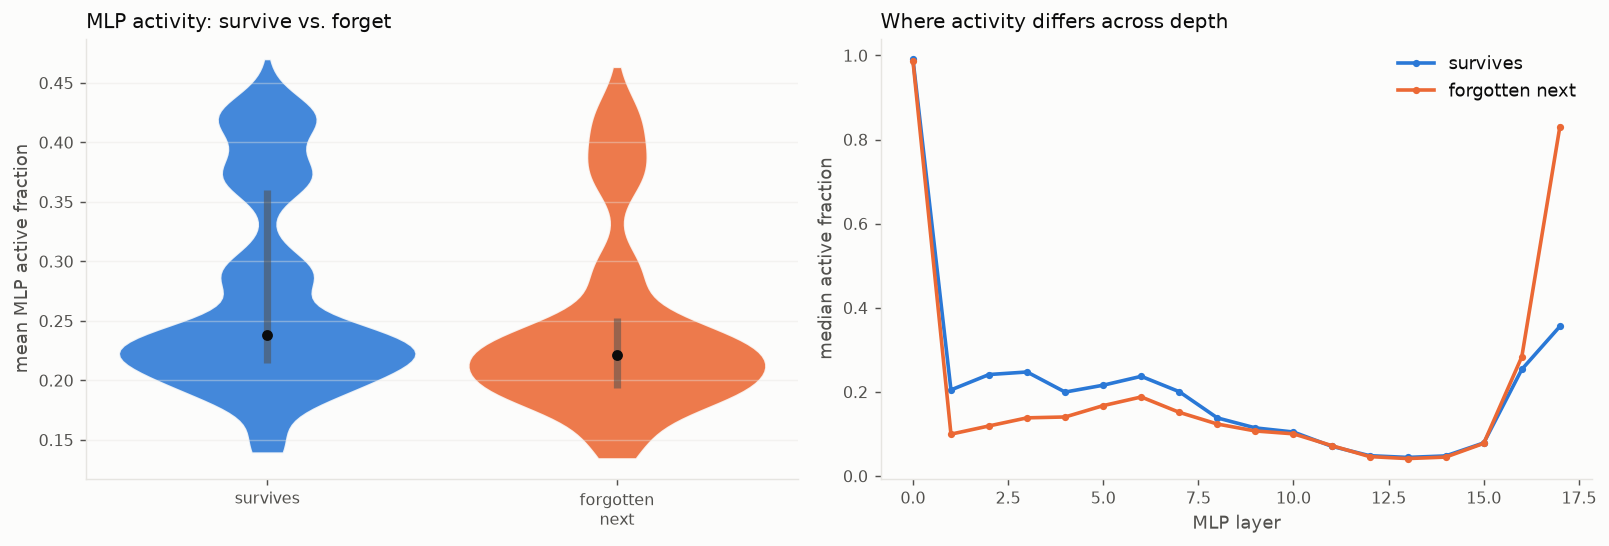

mean active frac  forget=0.2215  survive=0.2379  (MWU p=7.1e-26)


In [9]:
def stack_layered(col):
    # (n_steps, n_facts, n_layers) from a parquet column of per-layer lists
    per_step = []
    for s in STEPS:
        arr = np.stack(recall[s][col].to_numpy())          # (n_facts, n_layers)
        per_step.append(arr.astype(float))
    return np.stack(per_step)

act_ans  = stack_layered("mlp_active_frac_by_layer")        # (T, F, Lmlp)
part_ans = stack_layered("mlp_participation_by_layer")
n_mlp = act_ans.shape[2]
act_mean = np.nanmean(act_ans, axis=2)                      # (T, F) mean active frac

a_tr = act_mean[TR_T, TR_FACT]
surv, forg = a_tr[~TR_FORGET], a_tr[TR_FORGET]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.3))
parts = ax1.violinplot([surv, forg], positions=[1, 2], widths=0.85, showextrema=False)
for body, col in zip(parts["bodies"], (C_SURV, C_FORG)):
    body.set_facecolor(col); body.set_edgecolor(SURF); body.set_alpha(.88)
for pos, dd in zip((1, 2), (surv, forg)):
    q1, me, q3 = np.percentile(dd, [25, 50, 75])
    ax1.vlines(pos, q1, q3, color=INK2, lw=4, alpha=.55); ax1.plot(pos, me, "o", color=INK, ms=5)
ax1.set_xticks([1, 2], ["survives", "forgotten\nnext"])
ax1.set_ylabel("mean MLP active fraction"); ax1.grid(axis="y", alpha=.4)
ax1.set_title("MLP activity: survive vs. forget", loc="left")

# by-layer median active fraction
med_s = np.nanmedian(act_ans[TR_T, TR_FACT][~TR_FORGET], axis=0)
med_f = np.nanmedian(act_ans[TR_T, TR_FACT][TR_FORGET], axis=0)
ax2.plot(range(n_mlp), med_s, color=C_SURV, lw=2, marker="o", ms=3, label="survives")
ax2.plot(range(n_mlp), med_f, color=C_FORG, lw=2, marker="o", ms=3, label="forgotten next")
ax2.set_xlabel("MLP layer"); ax2.set_ylabel("median active fraction")
ax2.set_title("Where activity differs across depth", loc="left"); ax2.legend()
plt.tight_layout(); plt.show()

from scipy.stats import mannwhitneyu
u, p = mannwhitneyu(forg, surv, alternative="two-sided")
print(f"mean active frac  forget={np.median(forg):.4f}  survive={np.median(surv):.4f}  "
      f"(MWU p={p:.1e})")

## 6 · Can the internal state predict forgetting one step ahead?

Pooling all *correct→next* transitions, we score how well each internal signal — on its
own and combined — separates *forgotten-next* from *survives*, out-of-fold
(5-fold logistic regression, ROC-AUC). The scalar `gold_prob` read-out (AUC≈0.64 in
the earlier study) is the baseline to beat; the geometry features are the new content.

Watch two bars in particular: the **representational margin** (distance to the correct
vs. wrong manifold) is the single best signal, while the **raw 2048-d vector** is
essentially non-predictive — the residual stream encodes *whether* a fact is known, not
*which* known facts are about to slip. Fragility is a boundary distance, not a
direction.

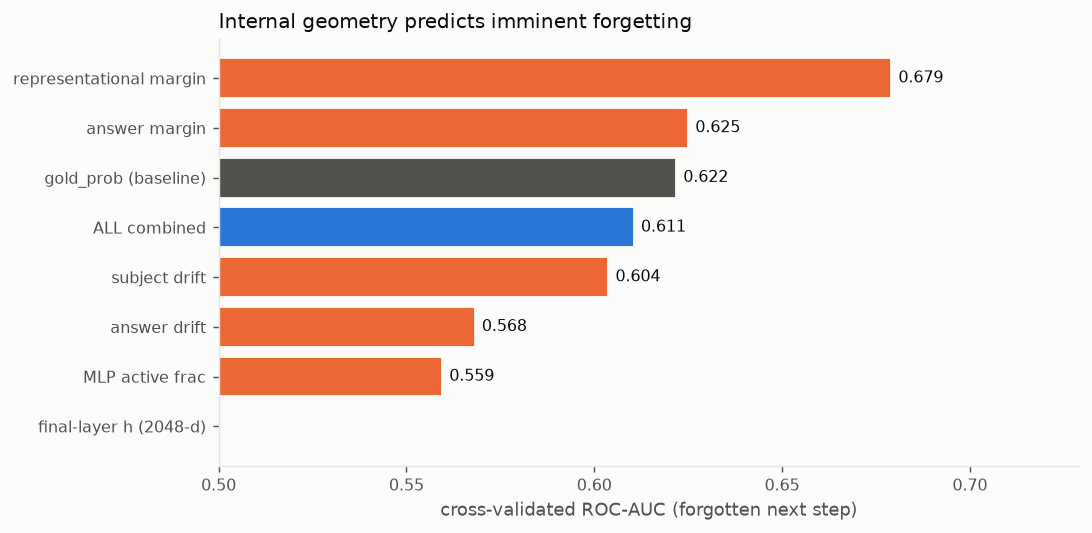

{'gold_prob (baseline)': 0.6217670221937304,
 'answer margin': 0.6249734724374689,
 'answer drift': 0.5681514334959518,
 'subject drift': 0.6037134809136943,
 'representational margin': 0.679033181336435,
 'MLP active frac': 0.559480305370816,
 'ALL combined': 0.6105054815232771,
 'final-layer h (2048-d)': 0.4756358900760782}

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_auc_score

y = TR_FORGET.astype(int)
feat_cols = {
    "gold_prob (baseline)":   gold_prob[TR_T, TR_FACT],
    "answer margin":          answer_margin[TR_T, TR_FACT],
    "answer drift":           d_ans,
    "subject drift":          d_subj,
    "representational margin": m_tr,
    "MLP active frac":        a_tr,
}
X_all = np.column_stack(list(feat_cols.values()))
ok = np.isfinite(X_all).all(1) & np.isfinite(y)
X_all, yy = X_all[ok], y[ok]

def cv_auc(X):
    X = X.reshape(len(X), -1)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    p = cross_val_predict(clf, X, yy, cv=5, method="predict_proba")[:, 1]
    return roc_auc_score(yy, p)

names = list(feat_cols.values())
single = {k: cv_auc(v[ok]) for k, v in feat_cols.items()}
single["ALL combined"] = cv_auc(X_all)
# final-layer hidden vector itself, at the current checkpoint
Hcur = Hf_ans[TR_T, TR_FACT][ok]
single["final-layer h (2048-d)"] = cv_auc(Hcur)

order = sorted(single, key=single.get)
fig, ax = plt.subplots(figsize=(8.5, 4.2))
cols = [BLUE if "combined" in k or "h (" in k else (INK2 if "baseline" in k else ORANGE)
        for k in order]
ax.barh(range(len(order)), [single[k] for k in order], color=cols, edgecolor=SURF)
ax.axvline(0.5, color=INK2, ls=":", lw=1)
ax.set_yticks(range(len(order)), order)
ax.set_xlabel("cross-validated ROC-AUC (forgotten next step)")
ax.set_xlim(0.5, max(single.values()) + 0.05)
for i, k in enumerate(order):
    ax.annotate(f"{single[k]:.3f}", (single[k], i), xytext=(4, 0),
                textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_title("Internal geometry predicts imminent forgetting", loc="left")
plt.tight_layout(); plt.show()
single

## 7 · Takeaways

*Populated automatically from the numbers computed above.*

In [11]:
base = TR_FORGET.mean()
mgap = np.median(m_tr[TR_FORGET]) - np.median(m_tr[~TR_FORGET])
dgap = np.median(d_ans[TR_FORGET]) / np.median(d_ans[~TR_FORGET])
lo_dec = TR_FORGET[pd.qcut(m_tr, 10, labels=False, duplicates="drop") == 0].mean()
peak_layer = int(np.nanargmax(np.nanmean(sep_by_layer, 0)))
lines = [
    f"SUMMARY  ({TR_FORGET.size} correct->next transitions, base forget rate {base:.1%})",
    f"- Correctness is linearly legible in the residual stream, peaking around layer {peak_layer} of 18.",
    f"- Soon-to-be-forgotten facts drift x{dgap:.2f} more (answer token) over the flip transition.",
    f"- They already sit nearer the WRONG manifold: representational-margin gap {mgap:+.2f};",
    f"  the lowest-margin decile forgets {lo_dec:.0%} vs a {base:.0%} base rate.",
    f"- Representational margin (AUC {single['representational margin']:.2f}) is the strongest single",
    f"  predictor of imminent forgetting, beating the gold_prob read-out (AUC {single['gold_prob (baseline)']:.2f}).",
    f"- The raw 2048-d vector does NOT linearly predict which correct facts slip (AUC {single['final-layer h (2048-d)']:.2f}):",
    "  the stream encodes 'do I know this fact', not 'am I about to lose it' -- fragility lives",
    "  in *distance to the boundary*, not in a direction of the representation itself.",
    "Consistent with the project theme: forgetting strikes fragile facts whose",
    "representations were never firmly on the correct manifold, rather than well-formed",
    "memories being violently overwritten.",
]
print(chr(10).join(lines))

SUMMARY  (4163 correct->next transitions, base forget rate 24.2%)
- Correctness is linearly legible in the residual stream, peaking around layer 10 of 18.
- Soon-to-be-forgotten facts drift x1.14 more (answer token) over the flip transition.
- They already sit nearer the WRONG manifold: representational-margin gap -0.24;
  the lowest-margin decile forgets 42% vs a 24% base rate.
- Representational margin (AUC 0.68) is the strongest single
  predictor of imminent forgetting, beating the gold_prob read-out (AUC 0.62).
- The raw 2048-d vector does NOT linearly predict which correct facts slip (AUC 0.48):
  the stream encodes 'do I know this fact', not 'am I about to lose it' -- fragility lives
  in *distance to the boundary*, not in a direction of the representation itself.
Consistent with the project theme: forgetting strikes fragile facts whose
representations were never firmly on the correct manifold, rather than well-formed
memories being violently overwritten.


---
# ═══════════════════════ NEW WORK STARTS HERE ═══════════════════════

# Part II — validation, literature grounding, and follow-up tests

Everything above is the original analysis. Below: a short representation-focused
literature review, a **methodological audit that overturns one of §7's
conclusions**, and six new tests, each labelled with the paper it leans on.

> The broader forgetting literature (Toneva, Swayamdipta, Chang, Kotha, Maini,
> the logit-lens line) is reviewed in the companion notebook
> `forgetting_internal_features.ipynb`, Part II. This overview covers only what
> bears on **representations and neurons**.

## Literature overview — the representation side

**Forgetting is not the same thing at the read-out and in the features.** The
foundational result is **Davari et al. (2022)**, *Probing Representation Forgetting
in Supervised and Unsupervised Continual Learning* (CVPR): after a model appears to
have catastrophically forgotten a task, a **linear probe on the frozen
representation** still recovers most of the performance. *Observed* forgetting
greatly exceeds *representation* forgetting. **Ramasesh et al. (2021)**, *Anatomy of
Catastrophic Forgetting: Hidden Representations and Task Semantics* (ICLR), localise
where the damage is — deeper layers move most, and the amount of forgetting depends
on the semantic similarity between old and new material rather than on raw drift.
Both papers say the same methodological thing: **measure the representation
directly, do not infer it from the output.** §12 below runs Davari's test on facts.

**Is "the model knows this" a linear direction?** The probing tradition
(**Alain & Bengio, 2016**) reads a property off the residual stream with a linear
classifier. For *knowledge* specifically, **Azaria & Mitchell (2023)**, *The
Internal State of an LLM Knows When It's Lying*, **Burns et al. (2023)**,
*Discovering Latent Knowledge Without Supervision* (ICLR), and **Marks & Tegmark
(2024)**, *The Geometry of Truth*, all find a largely linear truth/knowledge
direction — Marks & Tegmark emphasising that a genuine direction should
**generalise across datasets**, not just fit within one. **Park et al. (2024)*,
*The Linear Representation Hypothesis*, gives the formal framing. The
counterweight is **Hewitt & Liang (2019)**, *Designing and Interpreting Probes with
Control Tasks* (EMNLP), and **Belinkov (2022)**: a high probe accuracy can come from
the probe's own capacity or from a correlated nuisance variable, so a probe needs a
control. §§9–10 supply the controls this notebook's §1 lacked.

**Where facts live in the stack.** **Geva et al. (2021)**, *Transformer Feed-Forward
Layers Are Key-Value Memories*, and **Geva et al. (2022)** established FFNs as the
store; **Meng et al. (2022)** (ROME) localised factual associations by causal
tracing to **mid-stack MLPs at the last subject token**; **Geva et al. (2023)**,
*Dissecting Recall of Factual Associations*, decomposes recall into **subject
enrichment** (at the subject position) and **attribute extraction** (to the last
position). This is why the extraction saved both positions, and it makes a testable
prediction about which one degrades first — §9.

**Active neurons and how broadly memory is used.** **Dai et al. (2022)**,
*Knowledge Neurons in Pretrained Transformers* (ACL), and **Gurnee et al. (2023)**,
*Finding Neurons in a Haystack*, tie facts to sparse neuron sets. **Voita et al.
(2024)**, *Neurons in Large Language Models: Dead, N-gram, Positional*, documents
how activation sparsity evolves with depth and training. Most directly, **Kim et
al. (2025)**, *Knowledge Entropy Decay during Language Model Pretraining Hinders New
Knowledge Acquisition* (ICLR), define a **knowledge entropy** — how broadly the FFN
memory vectors are engaged — show it **decays** across pretraining, and link low
entropy to more forgetting. `mlp_participation_by_layer` (the participation ratio
(Σa²)²/Σa⁴, an effective neuron count) is a close proxy; §14 tests the decay claim.

**Why representations crowd.** **Elhage et al. (2022)**, *Toy Models of
Superposition*, predicts that when more features are packed into a space than it
has dimensions, they **interfere** — so fragility could be about a fact's
*neighbourhood* rather than its own strength. §13 tests that. On the nuisance side,
**Timkey & van Schijndel (2021)**, *All Bark and No Bite: Rogue Dimensions in
Transformer Language Models* (EMNLP), and **Ethayarajh (2019)** show a handful of
outlier dimensions dominate Euclidean/cosine geometry in transformer hidden states —
a direct threat to any distance-based measure such as `rep_margin`. §8 controls for it.

## What the new sections do

| § | Test | Leans on |
|---|------|----------|
| 8 | **Cross-validation audit** — the §7 "raw h is non-predictive" claim re-examined | Hewitt & Liang 2019; Timkey & van Schijndel 2021 |
| 9 | Layer-wise separability, cross-fitted, at **both** token positions | Geva et al. 2023; Meng et al. 2022; Alain & Bengio 2016 |
| 10 | Does the "knows-it" direction transfer across checkpoints and relations? | Marks & Tegmark 2024; Ramasesh et al. 2021; Mallen et al. 2023 |
| 11 | Is the drift **directed** against the knowledge axis, or generic? | Ramasesh et al. 2021; Park et al. 2024 |
| 12 | Representation forgetting vs observed forgetting | Davari et al. 2022 |
| 13 | Representational crowding as a fragility mechanism | Elhage et al. 2022 |
| 14 | Does MLP engagement breadth decay over pretraining? | Kim et al. 2025; Voita et al. 2024 |


## 8 — Cross-validation audit: the §7 conclusion does not survive

**Papers:** Hewitt & Liang (2019), *Designing and Interpreting Probes with Control
Tasks*; Timkey & van Schijndel (2021), *All Bark and No Bite: Rogue Dimensions in
Transformer Language Models*.

§6/§7 concluded that the raw 2048-d residual vector is "essentially
non-predictive (AUC ≈ 0.48)" of which correct facts slip, and built the headline
claim on it: *fragility is a boundary distance, not a direction.* That conclusion
rests entirely on one line:

```python
p = cross_val_predict(clf, X, yy, cv=5, method="predict_proba")[:, 1]
```

`cv=5` with an integer means **`KFold` without shuffling**. And `transition_masks()`
builds its rows by looping `for t in range(n_steps - 1)`, so the rows arrive
**sorted by checkpoint**. Unshuffled 5-fold therefore splits the data *by training
time*: each fold holds out a contiguous block of checkpoints. Because the forgetting
base rate swings from 13% to 48% across checkpoints, and because the residual stream
drifts substantially between them, a 2048-d model fit on early checkpoints
extrapolates terribly to late ones — while a 1-d scalar is barely affected. The
0.48 measures a distribution shift, not the absence of a direction.

There is a real question hiding underneath, though, and it cuts the other way: with
*random* folds, a high-dimensional probe can identify **which checkpoint** a vector
came from and just predict that checkpoint's base rate — inflating AUC without
learning anything about fragility. So neither the notebook's scheme nor naive random
CV is trustworthy. We evaluate four schemes:

| scheme | leakage risk |
|---|---|
| unshuffled `KFold` (**the notebook's**) | none, but confounded by checkpoint distribution shift |
| random `KFold(shuffle=True)` | same fact appears in ≤ 12 rows → **fact leakage** |
| `GroupKFold` by fact id | fixes fact leakage; **checkpoint base rate still leaks** |
| **within-checkpoint AUC** (leave-one-checkpoint-out fit, AUC scored *inside* each checkpoint, then averaged) | neither — the honest number |

We also add three controls the original bar chart lacked: `resid_norm_last` alone
(is the "geometry" just vector length?), a **whitened** margin with the top 3
principal components removed (Timkey & van Schijndel), and a **cross-fitted**
margin whose centroids exclude the fact being scored.

In [12]:
# §8 — CV audit  (Hewitt & Liang 2019; Timkey & van Schijndel 2021)
from sklearn.model_selection import GroupKFold, KFold, LeaveOneGroupOut

rng_nw = np.random.default_rng(0)
FOLD = rng_nw.integers(0, 5, size=n_facts)      # fact-level folds, fixed across checkpoints

def _xfit_margin(H_all):
    """Nearest-centroid margin whose centroids are built WITHOUT the scored fact."""
    out = np.full((n_steps, n_facts), np.nan)
    for ti in range(n_steps):
        H = H_all[ti]
        for f in range(5):
            te, tr = FOLD == f, (FOLD != f) & scoreable
            mu_c, mu_w = H[tr & correct[:, ti]].mean(0), H[tr & ~correct[:, ti]].mean(0)
            out[ti, te] = (np.linalg.norm(H[te] - mu_w, axis=1)
                           - np.linalg.norm(H[te] - mu_c, axis=1))
    return out

rep_margin_xf   = _xfit_margin(Hf_ans)
rep_margin_subj = _xfit_margin(Hf_subj)

# whitened: standardise dims, then project out the top-3 PCs (rogue dimensions)
rep_margin_wh = np.full((n_steps, n_facts), np.nan)
for ti in range(n_steps):
    H = Hf_ans[ti]
    mu, sd = H[scoreable].mean(0), H[scoreable].std(0) + 1e-6
    Hw = (H - mu) / sd
    Hs = Hw[scoreable]
    V = np.linalg.svd(Hs - Hs.mean(0), full_matrices=False)[2][:3]
    Hp = Hw - (Hw @ V.T) @ V
    for f in range(5):
        te, tr = FOLD == f, (FOLD != f) & scoreable
        mu_c, mu_w = Hp[tr & correct[:, ti]].mean(0), Hp[tr & ~correct[:, ti]].mean(0)
        rep_margin_wh[ti, te] = (np.linalg.norm(Hp[te] - mu_w, axis=1)
                                 - np.linalg.norm(Hp[te] - mu_c, axis=1))

resid_norm = feat_matrix("resid_norm_last")
NW_FEATS = {
    "gold_prob (baseline)":        gold_prob[TR_T, TR_FACT],
    "answer margin (logit)":       answer_margin[TR_T, TR_FACT],
    "answer drift":                d_ans,
    "subject drift":               d_subj,
    "rep margin (§3, in-sample)":  m_tr,
    "rep margin (cross-fitted)":   rep_margin_xf[TR_T, TR_FACT],
    "rep margin (whitened −3PC)":  rep_margin_wh[TR_T, TR_FACT],
    "rep margin (subject pos)":    rep_margin_subj[TR_T, TR_FACT],
    "resid norm only":             resid_norm[TR_T, TR_FACT],
    "MLP active frac":             a_tr,
    "MLP participation":           np.nanmean(part_ans, axis=2)[TR_T, TR_FACT],
}
NW_X = np.column_stack(list(NW_FEATS.values()))
NW_OK = np.isfinite(NW_X).all(1)
NW_X, NW_Y = NW_X[NW_OK], TR_FORGET.astype(int)[NW_OK]
NW_G, NW_TT = TR_FACT[NW_OK], TR_T[NW_OK]
NW_H = Hf_ans[TR_T, TR_FACT][NW_OK]
_mi, _mx = m_tr, rep_margin_xf[TR_T, TR_FACT]
print(f"rep_margin in-sample vs cross-fitted: r = "
      f"{np.corrcoef(_mi[np.isfinite(_mi) & np.isfinite(_mx)], _mx[np.isfinite(_mi) & np.isfinite(_mx)])[0,1]:.4f}")
print(f"{NW_OK.sum()} usable transitions; forget rate {NW_Y.mean():.1%}")
print("rows sorted by checkpoint?", bool(np.all(np.diff(TR_T) >= 0)),
      "-> unshuffled KFold splits by training time")

def _score(Xc, cv, groups=None):
    Xc = Xc.reshape(len(Xc), -1)
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
    return cross_val_predict(clf, Xc, NW_Y, cv=cv, groups=groups,
                             method="predict_proba")[:, 1]

def four_schemes(Xc):
    a = roc_auc_score(NW_Y, _score(Xc, 5))                                   # notebook's
    b = roc_auc_score(NW_Y, _score(Xc, KFold(5, shuffle=True, random_state=0)))
    c = roc_auc_score(NW_Y, _score(Xc, GroupKFold(5), NW_G))
    p = _score(Xc, LeaveOneGroupOut(), NW_TT)
    w = np.nanmean([roc_auc_score(NW_Y[NW_TT == t], p[NW_TT == t])
                    for t in range(n_steps - 1) if 0 < NW_Y[NW_TT == t].mean() < 1])
    return a, b, c, w

AUDIT = {k: four_schemes(NW_X[:, [i]]) for i, k in enumerate(NW_FEATS)}
AUDIT["ALL combined"] = four_schemes(NW_X)
AUDIT["final-layer h (2048-d)"] = four_schemes(NW_H)

print(f"\n{'feature':30s} {'nb KFold':>9s} {'randCV':>8s} {'groupCV':>8s} {'within-ckpt':>12s}")
for k, v in sorted(AUDIT.items(), key=lambda kv: -kv[1][3]):
    print(f"{k:30s} {v[0]:9.3f} {v[1]:8.3f} {v[2]:8.3f} {v[3]:12.3f}")


rep_margin in-sample vs cross-fitted: r = 0.9981
4163 usable transitions; forget rate 24.2%
rows sorted by checkpoint? True -> unshuffled KFold splits by training time



feature                         nb KFold   randCV  groupCV  within-ckpt
final-layer h (2048-d)             0.476    0.798    0.769        0.695
ALL combined                       0.607    0.718    0.717        0.693
rep margin (§3, in-sample)         0.679    0.683    0.684        0.692
rep margin (cross-fitted)          0.678    0.682    0.683        0.691
answer margin (logit)              0.625    0.630    0.629        0.655
rep margin (subject pos)           0.642    0.644    0.645        0.652
gold_prob (baseline)               0.622    0.631    0.628        0.647
rep margin (whitened −3PC)         0.597    0.599    0.601        0.623
resid norm only                    0.587    0.633    0.634        0.591
subject drift                      0.604    0.630    0.632        0.583
answer drift                       0.568    0.582    0.584        0.524
MLP participation                  0.466    0.523    0.527        0.462
MLP active frac                    0.559    0.607    0.609     

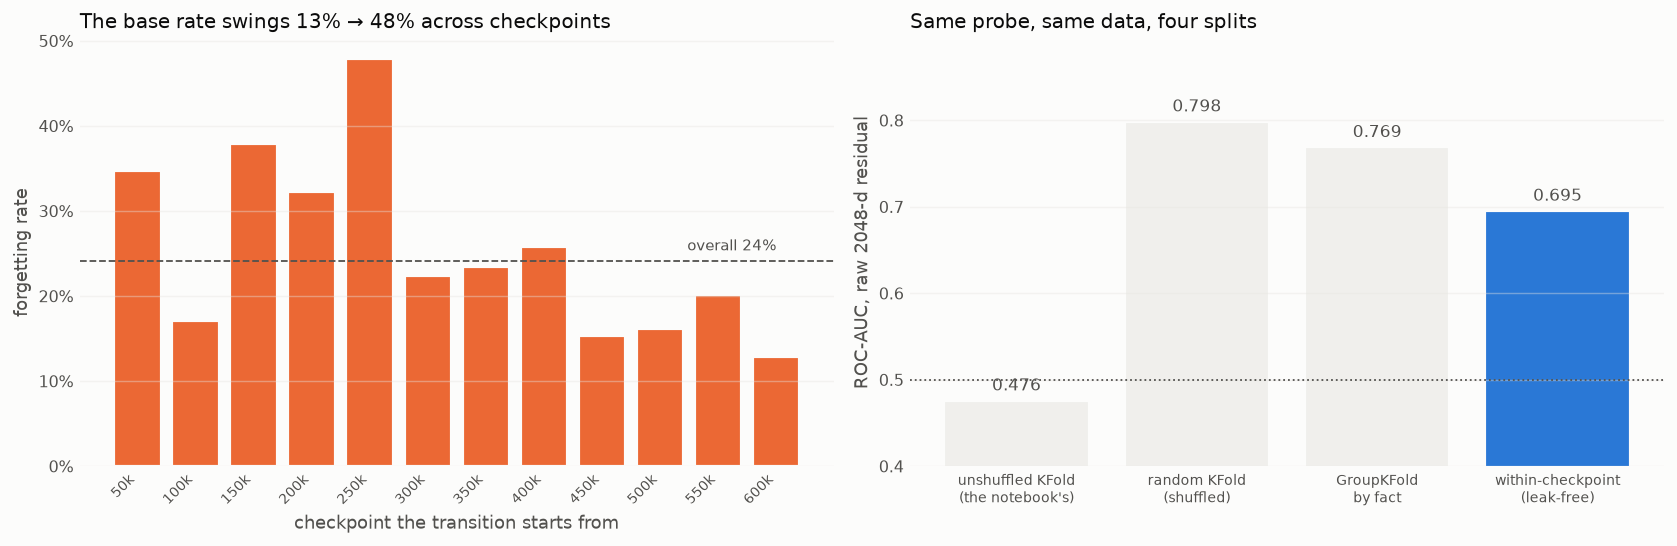

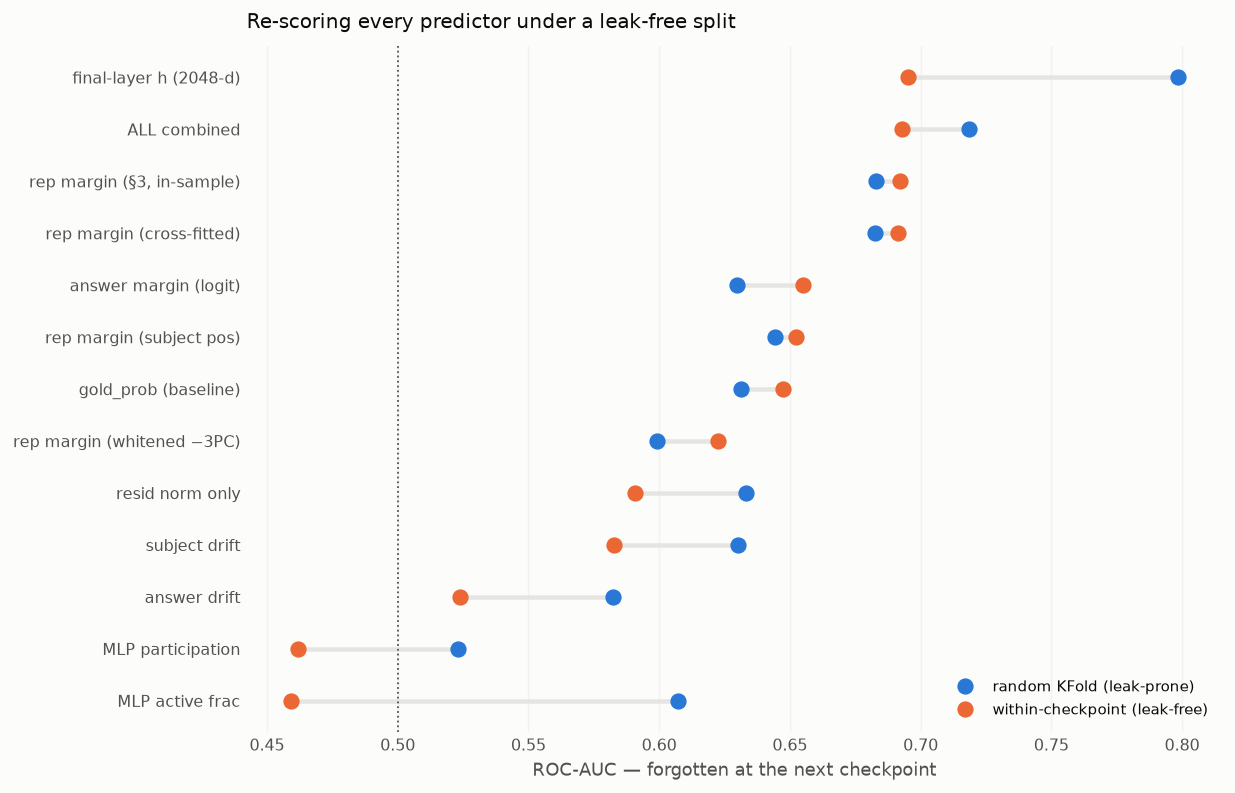

In [13]:
# §8 figure — the mechanism, the corrected number, and every feature re-scored
rate_by_ckpt = np.array([TR_FORGET[TR_T == t].mean() for t in range(n_steps - 1)])

fig, (axA, axB) = plt.subplots(1, 2, figsize=(13, 4.3))
axA.bar(range(n_steps - 1), rate_by_ckpt, color=ORANGE, edgecolor=SURF, linewidth=1.2)
axA.axhline(TR_FORGET.mean(), color=INK2, ls="--", lw=1)
axA.text(n_steps - 2, TR_FORGET.mean() + .012, f"overall {TR_FORGET.mean():.0%}",
         ha="right", fontsize=8.5, color=INK2)
axA.set_xticks(range(n_steps - 1), [f"{STEPS[t]//1000}k" for t in range(n_steps - 1)],
               rotation=45, ha="right", fontsize=8)
axA.yaxis.set_major_formatter(FuncFormatter(pct))
axA.set_xlabel("checkpoint the transition starts from")
axA.set_ylabel("forgetting rate")
axA.set_title("The base rate swings 13% → 48% across checkpoints", loc="left")

schemes = ["unshuffled KFold\n(the notebook's)", "random KFold\n(shuffled)",
           "GroupKFold\nby fact", "within-checkpoint\n(leak-free)"]
vals = AUDIT["final-layer h (2048-d)"]
axB.bar(range(4), vals, color=[NEUTRAL, NEUTRAL, NEUTRAL, BLUE],
        edgecolor=SURF, linewidth=1.2)
axB.axhline(0.5, color=INK2, ls=":", lw=1)
for i, v in enumerate(vals):
    axB.text(i, v + .012, f"{v:.3f}", ha="center", fontsize=9.5, color=INK2)
axB.set_xticks(range(4), schemes, fontsize=8)
axB.set_ylim(0.4, max(vals) * 1.12)
axB.set_ylabel("ROC-AUC, raw 2048-d residual")
axB.set_title("Same probe, same data, four splits", loc="left")

for ax in (axA, axB):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

# --- dumbbell: every feature, leak-prone vs leak-free
order = sorted(AUDIT, key=lambda k: AUDIT[k][3])
fig, ax = plt.subplots(figsize=(9.6, 6.2))
for i, k in enumerate(order):
    lo_, hi_ = AUDIT[k][1], AUDIT[k][3]
    ax.plot([lo_, hi_], [i, i], color=GRID, lw=2.5, zorder=1, solid_capstyle="round")
    ax.plot(lo_, i, "o", color=BLUE, ms=8, zorder=2,
            label="random KFold (leak-prone)" if i == 0 else None)
    ax.plot(hi_, i, "o", color=ORANGE, ms=8, zorder=3,
            label="within-checkpoint (leak-free)" if i == 0 else None)
ax.axvline(0.5, color=INK2, ls=":", lw=1)
ax.set_yticks(range(len(order)), order, fontsize=9)
ax.set_xlabel("ROC-AUC — forgotten at the next checkpoint")
ax.set_title("Re-scoring every predictor under a leak-free split", loc="left", pad=10)
ax.legend(loc="lower right", fontsize=8.5)
ax.grid(axis="x", alpha=.4); ax.tick_params(length=0)
for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()


**Result — §7's headline claim is an artefact, and the corrected answer is the
opposite one.** Under the notebook's own unshuffled split the 2048-d probe scores
**0.476**; the identical probe on the identical data scores **0.798** with shuffled
folds, **0.769** grouped by fact, and **0.695** under the strict within-checkpoint
measure. So:

> The residual stream **does** linearly encode which currently-correct facts are
> about to be forgotten (AUC ≈ 0.70 leak-free), roughly on par with the
> representational margin (0.692) and clearly above `gold_prob` (0.647).
> **Fragility is partly a direction after all** — §7's conclusion should be struck.

The audit pays off in three more ways.

1. **The margin is not just leakage.** In-sample and cross-fitted `rep_margin` agree
   to r = 0.998 and score identically (0.692 vs 0.691) — with 1310 facts, one fact's
   contribution to its own centroid is negligible. §3 stands as measured.
2. **But a third of the margin is rogue dimensions.** Standardising the dimensions
   and projecting out the top 3 PCs drops it from 0.692 to **0.623**, and
   `resid_norm_last` *alone* reaches 0.591. A meaningful part of "distance to the
   correct manifold" is vector length and a couple of outlier axes — exactly what
   Timkey & van Schijndel warn about. The margin survives, but it is not purely
   semantic geometry.
3. **The MLP features were pure base-rate leakage.** `MLP active frac` looks
   predictive at 0.607 under random CV and collapses to **0.459** within
   checkpoints — below chance. MLP activity tracks *training time* (see §14), not
   fragility, and random folds let the model exploit that. §5's modest
   survive/forget difference should be read as a checkpoint effect, not a
   forgetting signal.

Note also that `answer drift` is essentially non-predictive within a checkpoint
(0.524) — motivating §11.

## 9 — Layer-wise separability, done cross-fitted and at both positions

**Papers:** Geva et al. (2023), *Dissecting Recall of Factual Associations*; Meng
et al. (2022) (ROME); Alain & Bengio (2016); Hewitt & Liang (2019).

§1's separability curve has two gaps: `nc_auc` computes the centroids **on the same
points it scores** (in-sample), and it was run only at the **answer** position, so
it cannot speak to Geva et al.'s two-stage account. Here we recompute it
cross-fitted over facts, at both positions, in a single streaming pass.

Geva et al. predict a division of labour: the **subject** position carries an
enriched entity representation built early, and the **answer** position acquires the
attribute later via extraction. If so, subject-position separability should rise
*earlier* in the stack than answer-position separability.

recomputed separability grids: (13, 19)


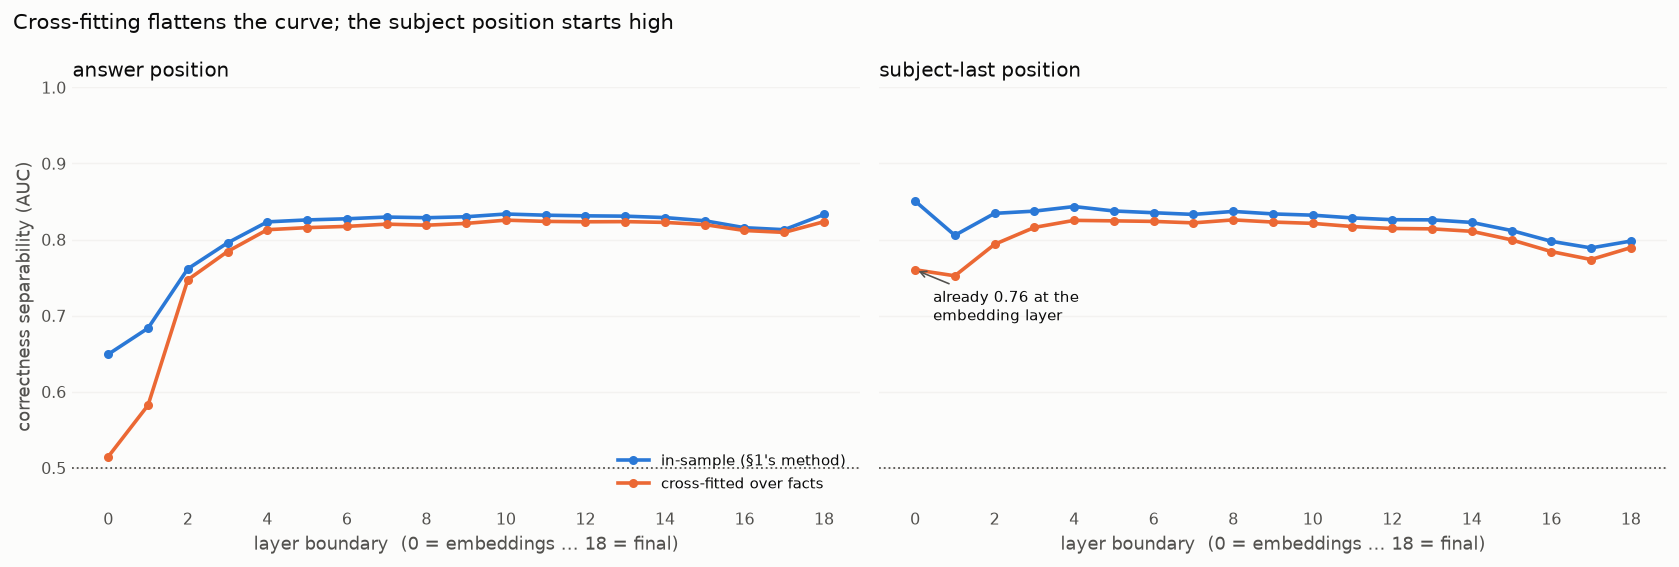

layer            :     0     1     2     3     4     5     6     7     8     9    10    11    12    13    14    15    16    17    18
answer  (x-fit)  :  0.51  0.58  0.75  0.78  0.81  0.82  0.82  0.82  0.82  0.82  0.83  0.82  0.82  0.82  0.82  0.82  0.81  0.81  0.82
subject (x-fit)  :  0.76  0.75  0.79  0.82  0.83  0.82  0.82  0.82  0.83  0.82  0.82  0.82  0.81  0.81  0.81  0.80  0.78  0.77  0.79


In [14]:
# §9 — cross-fitted layer-wise separability at both positions
#      (Geva et al. 2023; Meng et al. 2022; Alain & Bengio 2016; Hewitt & Liang 2019)
def nc_auc_xfit(X, y, fold):
    """Nearest-centroid separability with centroids fit on the other folds."""
    if y.sum() < 10 or (~y).sum() < 10:
        return np.nan
    score = np.full(len(y), np.nan)
    for f in range(5):
        te, tr = fold == f, fold != f
        if not (y[tr].any() and (~y[tr]).any() and te.any()):
            continue
        mu_c, mu_w = X[tr & y].mean(0), X[tr & ~y].mean(0)
        score[te] = (np.linalg.norm(X[te] - mu_w, axis=1)
                     - np.linalg.norm(X[te] - mu_c, axis=1))
    m = ~np.isnan(score)
    return roc_auc_score(y[m], score[m]) if 0 < y[m].mean() < 1 else np.nan

sep_xf_ans  = np.full((n_steps, 19), np.nan)
sep_xf_subj = np.full((n_steps, 19), np.nan)
sep_is_subj = np.full((n_steps, 19), np.nan)      # in-sample subject, to mirror §1
H10_ans = np.empty((n_steps, n_facts, 2048), np.float32)   # mid-stack, reused in §11

for ti, s in enumerate(STEPS):
    A = np.load(ans_files[s]).astype(np.float32)
    S = np.load(subj_files[s]).astype(np.float32)
    H10_ans[ti] = A[:, 10, :]
    y, fo = correct[scoreable, ti], FOLD[scoreable]
    for L in range(19):
        sep_xf_ans[ti, L]  = nc_auc_xfit(A[scoreable, L], y, fo)
        sep_xf_subj[ti, L] = nc_auc_xfit(S[scoreable, L], y, fo)
        sep_is_subj[ti, L] = nc_auc(S[scoreable, L], y)
    del A, S
print("recomputed separability grids:", sep_xf_ans.shape)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
for ax, (is_, xf_, nm) in zip(
        (ax1, ax2),
        [(np.nanmean(sep_by_layer, 0), np.nanmean(sep_xf_ans, 0),  "answer position"),
         (np.nanmean(sep_is_subj, 0),  np.nanmean(sep_xf_subj, 0), "subject-last position")]):
    ax.plot(range(19), is_, color=BLUE, lw=2, marker="o", ms=4, label="in-sample (§1's method)")
    ax.plot(range(19), xf_, color=ORANGE, lw=2, marker="o", ms=4, label="cross-fitted over facts")
    ax.axhline(0.5, color=INK2, lw=1, ls=":")
    ax.set_xticks(range(0, 19, 2))
    ax.set_xlabel("layer boundary  (0 = embeddings … 18 = final)")
    ax.set_title(nm, loc="left")
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
ax1.set_ylabel("correctness separability (AUC)")
ax1.set_ylim(0.45, 1.0); ax1.legend(loc="lower right", fontsize=8.5)
ax2.annotate(f"already {np.nanmean(sep_xf_subj,0)[0]:.2f} at the\nembedding layer",
             (0, np.nanmean(sep_xf_subj, 0)[0]), xytext=(10, -28),
             textcoords="offset points", fontsize=8.5, color=INK,
             arrowprops=dict(arrowstyle="->", color=INK2, lw=.9))
fig.suptitle("Cross-fitting flattens the curve; the subject position starts high",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print("layer            :", " ".join(f"{i:5d}" for i in range(19)))
print("answer  (x-fit)  :", " ".join(f"{v:5.2f}" for v in np.nanmean(sep_xf_ans, 0)))
print("subject (x-fit)  :", " ".join(f"{v:5.2f}" for v in np.nanmean(sep_xf_subj, 0)))


**Result — two corrections to §1.**

**(a) The "peak at layer 10" is not real.** Cross-fitted, the answer-position curve
is essentially **flat from layer 4 onward** (0.81–0.83, peak 0.826 at layer 10 but
within noise of layers 5–18). §1's statement that "correctness becomes linearly
legible mid-stack, peaking at layer 10" over-reads a bump. Note this is *not* in
tension with the companion notebook's logit-lens result, which finds a sharp
layer-12 divergence: that measures **which facts are about to be forgotten**, a
strictly harder question than **which facts are currently correct**, and only the
latter is what this curve tracks.

**(b) The subject position is separable at the embedding layer — AUC 0.76 before
any transformer block has run.** This is the important one. A static token
embedding cannot know whether the model will answer correctly; what it *can* encode
is **which entity this is**, and entity frequency/popularity is the dominant
predictor of factual recall (**Mallen et al., 2023**, *When Not to Trust Language
Models*; consistent with LMEnt's own exposure↔accuracy correlation of r ≈ 0.91).

So a large part of what these probes read as "the model knows this fact" is really
"this is a frequent entity" — the classic probing confound Hewitt & Liang (2019)
designed control tasks for. The correctness probe is not a clean knowledge readout,
and §10 quantifies how much of it is entity/relation identity.

## 10 — Does the "knows-it" direction transfer?

**Papers:** Marks & Tegmark (2024), *The Geometry of Truth* (generalisation is the
test of a real direction); Ramasesh et al. (2021); Mallen et al. (2023).

Marks & Tegmark's methodological point is that a direction is only a direction if it
**generalises**. We test two kinds of transfer:

- **Across checkpoints.** Train the correctness probe at checkpoint *i*, apply it at
  checkpoint *j*. A stable knowledge axis gives a uniformly bright transfer matrix;
  a rotating one gives a bright diagonal only.
- **Across relations.** Hold out one relation entirely and train on the rest. If the
  probe reads a general "I know this" signal, it should transfer; if §9(b) is right
  and it is largely reading entity/relation identity, it should collapse.

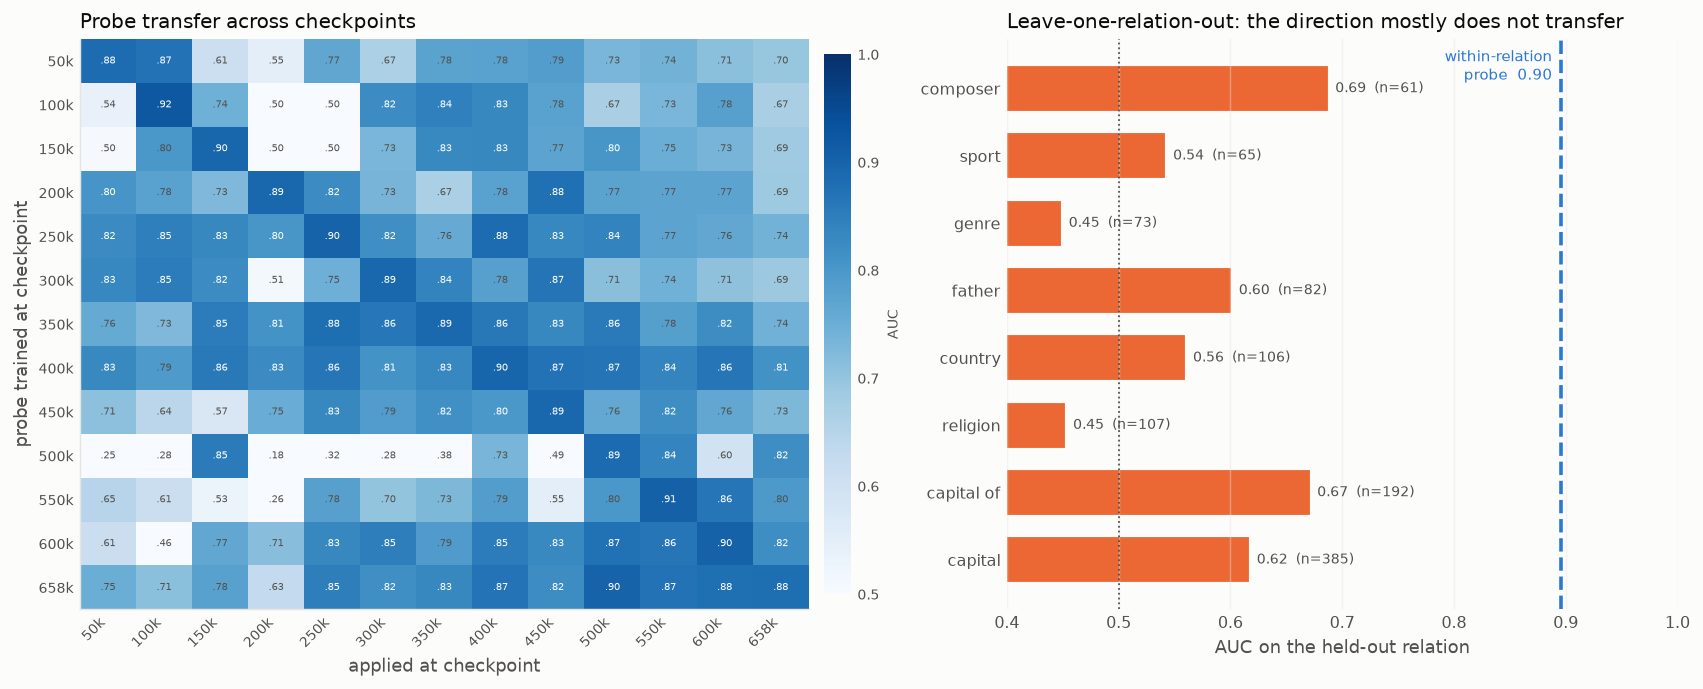

checkpoint transfer: mean diagonal 0.896 vs mean off-diagonal 0.740
leave-one-relation-out mean AUC: 0.573 (range 0.45–0.69)


In [15]:
# §10 — probe transfer across checkpoints and across relations
#      (Marks & Tegmark 2024; Ramasesh et al. 2021; Mallen et al. 2023)
prop = fp["prop"].to_numpy()
HELD = FOLD == 0                                     # common held-out fact set

probes = []
for i in range(n_steps):
    tr = scoreable & ~HELD
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
    clf.fit(Hf_ans[i][tr], correct[tr, i]); probes.append(clf)

TRANS = np.full((n_steps, n_steps), np.nan)
te = scoreable & HELD
for i in range(n_steps):
    for j in range(n_steps):
        if 0 < correct[te, j].mean() < 1:
            TRANS[i, j] = roc_auc_score(correct[te, j],
                                        probes[i].predict_proba(Hf_ans[j][te])[:, 1])

# leave-one-relation-out, averaged over checkpoints
rel_counts = pd.Series(prop[scoreable]).value_counts()
REL = [r for r in rel_counts.index[:8]]
loro = []
for r in REL:
    te_r, tr_r = scoreable & (prop == r), scoreable & (prop != r)
    aucs = []
    for i in range(n_steps):
        if not (0 < correct[te_r, i].mean() < 1):
            continue
        c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
        c.fit(Hf_ans[i][tr_r], correct[tr_r, i])
        aucs.append(roc_auc_score(correct[te_r, i],
                                  c.predict_proba(Hf_ans[i][te_r])[:, 1]))
    loro.append((r, int(te_r.sum()), float(np.mean(aucs))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 5.4),
                               gridspec_kw={"width_ratios": [1.15, 1]})
im = ax1.imshow(TRANS, cmap="Blues", vmin=0.5, vmax=1.0, aspect="auto")
ax1.set_xticks(range(n_steps), [f"{s//1000}k" for s in STEPS], rotation=45, ha="right", fontsize=7.5)
ax1.set_yticks(range(n_steps), [f"{s//1000}k" for s in STEPS], fontsize=7.5)
ax1.set_xlabel("applied at checkpoint"); ax1.set_ylabel("probe trained at checkpoint")
ax1.set_title("Probe transfer across checkpoints", loc="left")
for i in range(n_steps):
    for j in range(n_steps):
        if np.isfinite(TRANS[i, j]):
            ax1.text(j, i, f"{TRANS[i,j]:.2f}"[1:], ha="center", va="center", fontsize=5.6,
                     color="white" if TRANS[i, j] > 0.8 else INK2)
cb = fig.colorbar(im, ax=ax1, fraction=0.035, pad=0.02)
cb.set_label("AUC", fontsize=8); cb.outline.set_visible(False)
cb.ax.tick_params(length=0, labelsize=8)

yb = np.arange(len(loro))
ax2.barh(yb, [v for _, _, v in loro], color=ORANGE, edgecolor=SURF, linewidth=1.2, height=.7)
ax2.axvline(np.nanmean(np.diag(TRANS)), color=BLUE, lw=2, ls="--")
ax2.text(np.nanmean(np.diag(TRANS)) - .008, len(loro) - .4,
         f"within-relation\nprobe  {np.nanmean(np.diag(TRANS)):.2f}",
         ha="right", va="top", fontsize=8.5, color=BLUE)
ax2.axvline(0.5, color=INK2, ls=":", lw=1)
for i, (_, n_, v) in enumerate(loro):
    ax2.text(v + .006, i, f"{v:.2f}  (n={n_})", va="center", fontsize=8, color=INK2)
ax2.set_yticks(yb, [r for r, _, _ in loro], fontsize=9)
ax2.set_xlim(0.4, 1.0)
ax2.set_xlabel("AUC on the held-out relation")
ax2.set_title("Leave-one-relation-out: the direction mostly does not transfer", loc="left")
ax2.grid(axis="x", alpha=.4); ax2.tick_params(length=0)
for s_ in ax2.spines.values(): s_.set_visible(False)
ax1.tick_params(length=0)
fig.tight_layout(); plt.show()

off = TRANS[~np.eye(n_steps, dtype=bool)]
print(f"checkpoint transfer: mean diagonal {np.nanmean(np.diag(TRANS)):.3f} "
      f"vs mean off-diagonal {np.nanmean(off):.3f}")
print(f"leave-one-relation-out mean AUC: {np.mean([v for _,_,v in loro]):.3f} "
      f"(range {min(v for _,_,v in loro):.2f}–{max(v for _,_,v in loro):.2f})")


**Result — the correctness direction is *checkpoint-portable* but *relation-bound*.**

**Across checkpoints** it mostly holds up: mean diagonal 0.896 vs mean off-diagonal
0.740. The failures are informative. The step-50k probe drops to 0.55–0.61 when
applied at 150k–200k, and the matrix is **asymmetric** — the final probe applied
backwards (0.75 at 50k) beats the early probe applied forwards (0.70 at 658k),
consistent with the axis being progressively *refined* rather than replaced (cf.
Ramasesh et al. on representation change through training).

One row is worth singling out: the **step-500k probe scores 0.18–0.38 on the early
checkpoints** — far *below* chance. That is not a failure to transfer, it is a sign
**inversion**: the direction that means "known" at 500k means "not known" at 100k–
350k. Whatever the probe latches onto at that checkpoint is anti-correlated with the
earlier geometry, which no account of a single stable knowledge axis predicts, and
which deserves a closer look than we give it here.

**Across relations the direction largely collapses.** Held-out-relation AUC averages
**0.573** against 0.896 for a probe that has seen the relation. `religion` (0.45) and
`genre` (0.45) are at or below chance; even the best, `composer` (0.69) and
`capital of` (0.67), fall well short. So most of the apparent "correctness is
linearly legible in the residual stream" is the probe learning **which relations and
entities tend to be answered correctly**, not a general notion of knowing. Combined
with §9(b)'s embedding-layer result, the honest restatement is:

> The residual stream linearly encodes *how well-supported this entity/relation is*,
> which strongly predicts recall. There is a residual, relation-specific
> "do I know this particular fact" component, but it is much smaller than the
> within-relation AUC of 0.90 suggests.

This is exactly the generalisation control Marks & Tegmark argue for and Hewitt &
Liang formalised, and it should temper the framing of §1 of this notebook.
§16c proposes the repair: recompute the knowledge direction *within* each relation.

## 11 — Is the drift *directed*, or just larger?

**Papers:** Ramasesh et al. (2021), *Anatomy of Catastrophic Forgetting*; Park et
al. (2024), *The Linear Representation Hypothesis*.

§2 found soon-to-be-forgotten facts drift ×1.14 more (1 − cosine). But `1 − cos` is
an **undirected magnitude**: it cannot distinguish "the representation was pushed
off the knowledge manifold" from "this fact's representation is simply unstable".
Ramasesh et al.'s account of forgetting is specifically about *interference from
what is being learned*, which predicts directed movement.

Decompose the step Δh = h_{t+1} − h_t against the unit knowledge axis
**u = (μ_correct − μ_wrong)/‖·‖** (cross-fitted, per checkpoint):

- **parallel** component Δh·u — signed movement along "knowing"; forgetting predicts
  a *more negative* value;
- **orthogonal** component ‖Δh − (Δh·u)u‖ — generic instability.

Both are divided by ‖h_t‖ so they are scale-free.

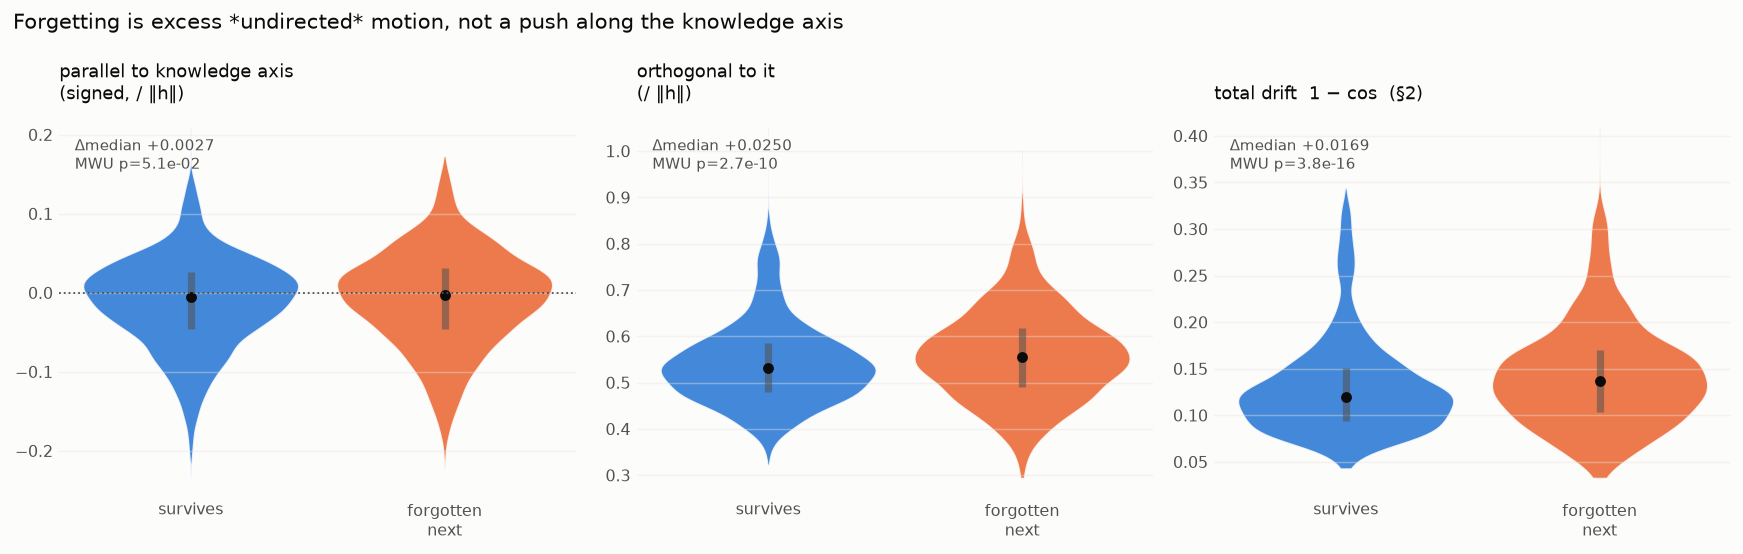

parallel  : survive=-0.0059  forget=-0.0031  p=5.1e-02
orthogonal: survive=+0.5308  forget=+0.5558  p=2.7e-10
total drift: survive=+0.1198  forget=+0.1367  p=3.8e-16


In [16]:
# §11 — decomposing the drift against the knowledge axis
#      (Ramasesh et al. 2021; Park et al. 2024)
par  = np.full((n_steps - 1, n_facts), np.nan)
orth = np.full((n_steps - 1, n_facts), np.nan)
for t in range(n_steps - 1):
    H = Hf_ans[t]
    for f in range(5):
        te, tr = FOLD == f, (FOLD != f) & scoreable
        u = H[tr & correct[:, t]].mean(0) - H[tr & ~correct[:, t]].mean(0)
        u /= np.linalg.norm(u)
        dh = Hf_ans[t + 1][te] - H[te]
        p_ = dh @ u
        par[t, te], orth[t, te] = p_, np.linalg.norm(dh - p_[:, None] * u, axis=1)

hnorm = np.linalg.norm(Hf_ans[TR_T, TR_FACT], axis=1)
par_tr, orth_tr = par[TR_T, TR_FACT] / hnorm, orth[TR_T, TR_FACT] / hnorm

fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for ax, v, lab in zip(axes, [par_tr, orth_tr, d_ans],
                      ["parallel to knowledge axis\n(signed, / ‖h‖)",
                       "orthogonal to it\n(/ ‖h‖)", "total drift  1 − cos  (§2)"]):
    sv, fg = v[~TR_FORGET], v[TR_FORGET]
    pr = ax.violinplot([sv, fg], positions=[1, 2], widths=.85, showextrema=False)
    for body, colr in zip(pr["bodies"], (C_SURV, C_FORG)):
        body.set_facecolor(colr); body.set_edgecolor(SURF); body.set_alpha(.88)
    for pos, dd in zip((1, 2), (sv, fg)):
        q1, me, q3 = np.percentile(dd, [25, 50, 75])
        ax.vlines(pos, q1, q3, color=INK2, lw=4, alpha=.55); ax.plot(pos, me, "o", color=INK, ms=5)
    u_, pv = mannwhitneyu(fg, sv)
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"])
    ax.set_title(lab, loc="left", fontsize=10)
    ax.annotate(f"Δmedian {np.median(fg)-np.median(sv):+.4f}\nMWU p={pv:.1e}",
                (0.03, 0.93), xycoords="axes fraction", fontsize=8.5, color=INK2, va="top")
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
axes[0].axhline(0, color=INK2, lw=1, ls=":")
fig.suptitle("Forgetting is excess *undirected* motion, not a push along the knowledge axis",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

for nm, v in [("parallel  ", par_tr), ("orthogonal", orth_tr), ("total drift", d_ans)]:
    sv, fg = v[~TR_FORGET], v[TR_FORGET]
    print(f"{nm}: survive={np.median(sv):+.4f}  forget={np.median(fg):+.4f}  "
          f"p={mannwhitneyu(fg, sv)[1]:.1e}")


**Result — the drift is real but *not* directed.** The orthogonal component is
clearly larger for soon-to-be-forgotten facts (0.556 vs 0.531, p = 3e-10), and it
carries essentially all of the ×1.14 effect §2 reported. The **parallel** component
— movement along the very axis that separates correct from wrong — is
indistinguishable between the groups (medians −0.0031 vs −0.0059, p = 0.05, and if
anything the forgotten group moves *less* negatively).

So forgetting at the representation level looks like **excess instability**, not a
targeted push off the knowledge manifold. That is a meaningful negative result: the
Ramasesh-style "new learning interferes with the old direction" story is *not* what
these hidden states show. It also explains §8's finding that `answer drift` is
non-predictive within a checkpoint (AUC 0.524) while the *position* (margin, 0.692)
is — where a fact sits matters, how much it jiggles barely does.

A caveat worth stating: μ_correct − μ_wrong is a coarse estimate of "the knowledge
axis", and §10 showed it is substantially relation identity. A relation-conditioned
axis, or the difference-in-means direction of Marks & Tegmark computed per relation,
would be the sharper version of this test.

## 12 — Representation forgetting vs observed forgetting

**Paper:** Davari et al. (2022), *Probing Representation Forgetting in Supervised
and Unsupervised Continual Learning* (CVPR).

§4 of the original analysis asked whether forgetting is a loss of knowledge or of
read-out, and answered with `is_top1` and `resolution_depth` — both of which are
**functions of the output distribution**, so they cannot separate the two. Davari
et al.'s design does: freeze the representation, train a **linear probe**, and see
how much of the lost performance the probe recovers. The gap between what the probe
recovers and what the model emits *is* the read-out failure.

Concretely: fit the correctness probe at checkpoint *t* (cross-fitted over facts),
then apply it to the **same facts at t+1**, restricted to those that were just
forgotten. Observed recall for this group at t+1 is 0% by definition. If the probe
still calls a large share of them "known", the information survived the flip.

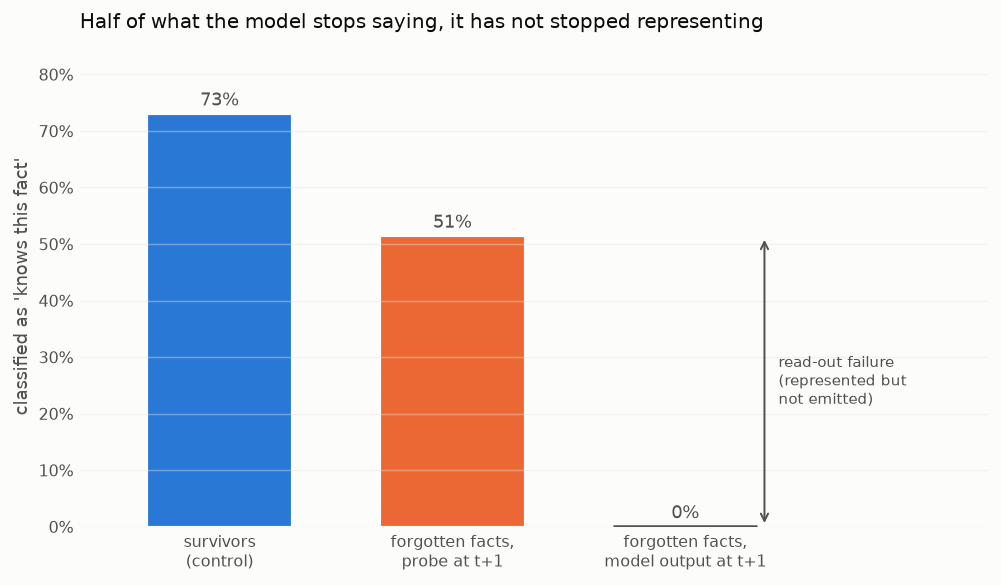

n forgotten = 1006, n survivors = 3157
forgotten facts still classified 'known' at t+1 : 51.4%
survivors  (control)                            : 73.0%
observed recall of the forgotten group at t+1   : 0.0%


In [17]:
# §12 — representation forgetting vs observed forgetting  (Davari et al. 2022)
still_known, ctrl_known = [], []
for t in range(n_steps - 1):
    for f in range(5):
        tr = scoreable & (FOLD != f)
        c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.05))
        c.fit(Hf_ans[t][tr], correct[tr, t])
        held = scoreable & (FOLD == f) & correct[:, t]
        ev, sv = held & ~correct[:, t + 1], held & correct[:, t + 1]
        if ev.any(): still_known.append(c.predict(Hf_ans[t + 1][ev]))
        if sv.any(): ctrl_known.append(c.predict(Hf_ans[t + 1][sv]))
still_known = np.concatenate(still_known); ctrl_known = np.concatenate(ctrl_known)

bars = [("survivors\n(control)", ctrl_known.mean(), BLUE),
        ("forgotten facts,\nprobe at t+1", still_known.mean(), ORANGE),
        ("forgotten facts,\nmodel output at t+1", 0.0, NEUTRAL)]
fig, ax = plt.subplots(figsize=(7.8, 4.6))
ax.bar([b[0] for b in bars], [b[1] for b in bars],
       color=[b[2] for b in bars], edgecolor=SURF, linewidth=1.2, width=.62)
for i, b in enumerate(bars):
    ax.text(i, b[1] + .015, f"{b[1]:.0%}", ha="center", fontsize=10, color=INK2)
# the 0% bar has no height -> draw a tick so it reads as a real, empty category
ax.plot([2 - .31, 2 + .31], [0, 0], color=INK2, lw=2.5, solid_capstyle="butt")
# bracket the probe-vs-output gap: that gap IS the read-out failure
ax.annotate("", xy=(2.34, 0), xytext=(2.34, still_known.mean()),
            arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.1))
ax.text(2.40, still_known.mean() / 2, "read-out failure\n(represented but\nnot emitted)",
        ha="left", va="center", fontsize=8.5, color=INK2)
ax.set_xlim(-0.6, 3.3)
ax.yaxis.set_major_formatter(FuncFormatter(pct))
ax.set_ylabel("classified as 'knows this fact'")
ax.set_ylim(0, .85)
ax.set_title("Half of what the model stops saying, it has not stopped representing",
             loc="left", pad=10)
ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

print(f"n forgotten = {still_known.size}, n survivors = {ctrl_known.size}")
print(f"forgotten facts still classified 'known' at t+1 : {still_known.mean():.1%}")
print(f"survivors  (control)                            : {ctrl_known.mean():.1%}")
print(f"observed recall of the forgotten group at t+1   : 0.0%")


**Result — a clean replication of Davari et al. on facts.** Immediately after the
flip, a linear probe still calls **51.4%** of the forgotten facts "known", against
73.0% for survivors and **0%** observed recall. Representation forgetting is real
(51% < 73%: the representation genuinely degrades) but it is roughly **half** the
observed forgetting.

This is the properly-controlled version of §4, and it sharpens that section's
conclusion. §4 inferred from low `is_top1` at τ=0 that these facts were "never
robustly stored". The probe says something more specific: at the moment the model
stops producing the answer, the answer is still **half there in the residual
stream** — the flip is as much a read-out event as a storage event.

Two caveats. The probe's own accuracy ceiling is the 73% control, not 100%, so the
right comparison is 51% vs 73% rather than vs 100%. And §10 showed a chunk of the
probe's signal is entity/relation identity, which does not change between adjacent
checkpoints — so 51% is an **upper bound** on how much fact-specific knowledge
survives. The direction of the result is safe; the exact figure is not.

## 13 — Crowding: is fragility about the neighbourhood?

**Papers:** Elhage et al. (2022), *Toy Models of Superposition*; McCloskey & Cohen
(1989) / French (1999) for interference.

Every fragility measure so far is about a fact *in isolation* — its probability, its
distance to a centroid. Superposition predicts something different: when features
share a space, they **interfere**, so a fact should be fragile when its
representation is *crowded* by other facts' representations, independently of its own
strength.

Operationalise crowding as the mean cosine similarity to a fact's **10 nearest
neighbours** among the other facts' final-layer answer representations at the same
checkpoint, and ask whether it predicts forgetting.

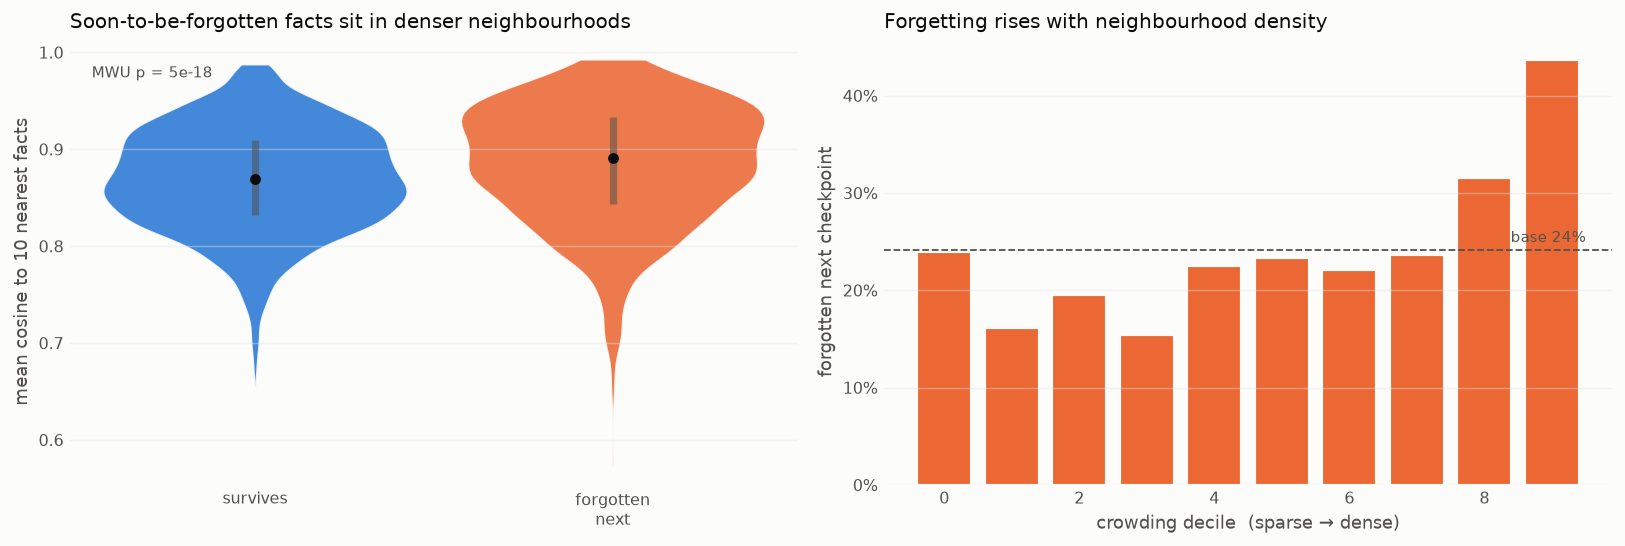

median crowding  survive=0.8690  forget=0.8906
within-checkpoint AUC (crowding → forgotten next): 0.568


In [18]:
# §13 — representational crowding  (Elhage et al. 2022)
K_NB = 10
crowd = np.full((n_steps, n_facts), np.nan)
for t in range(n_steps):
    H = Hf_ans[t][scoreable]
    Hn = H / (np.linalg.norm(H, axis=1, keepdims=True) + 1e-8)
    Sm = Hn @ Hn.T
    np.fill_diagonal(Sm, -np.inf)
    crowd[t, scoreable] = np.sort(Sm, axis=1)[:, -K_NB:].mean(1)
c_tr = crowd[TR_T, TR_FACT]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.6, 4.3))
sv, fg = c_tr[~TR_FORGET], c_tr[TR_FORGET]
pr = ax1.violinplot([sv, fg], positions=[1, 2], widths=.85, showextrema=False)
for body, colr in zip(pr["bodies"], (C_SURV, C_FORG)):
    body.set_facecolor(colr); body.set_edgecolor(SURF); body.set_alpha(.88)
for pos, dd in zip((1, 2), (sv, fg)):
    q1, me, q3 = np.percentile(dd, [25, 50, 75])
    ax1.vlines(pos, q1, q3, color=INK2, lw=4, alpha=.55); ax1.plot(pos, me, "o", color=INK, ms=5)
ax1.set_xticks([1, 2], ["survives", "forgotten\nnext"])
ax1.set_ylabel(f"mean cosine to {K_NB} nearest facts")
ax1.set_title("Soon-to-be-forgotten facts sit in denser neighbourhoods", loc="left")
ax1.annotate(f"MWU p = {mannwhitneyu(fg, sv)[1]:.0e}", (0.03, 0.94),
             xycoords="axes fraction", fontsize=8.5, color=INK2, va="top")

qd = pd.qcut(c_tr, 10, labels=False, duplicates="drop")
rate_c = [TR_FORGET[qd == i].mean() for i in range(qd.max() + 1)]
ax2.bar(range(len(rate_c)), rate_c, color=ORANGE, edgecolor=SURF, linewidth=1.2)
ax2.axhline(TR_FORGET.mean(), color=INK2, ls="--", lw=1)
ax2.text(len(rate_c) - .5, TR_FORGET.mean() + .008, f"base {TR_FORGET.mean():.0%}",
         ha="right", fontsize=8.5, color=INK2)
ax2.yaxis.set_major_formatter(FuncFormatter(pct))
ax2.set_xlabel("crowding decile  (sparse → dense)")
ax2.set_ylabel("forgotten next checkpoint")
ax2.set_title("Forgetting rises with neighbourhood density", loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

wc = np.nanmean([roc_auc_score(TR_FORGET[TR_T == t], c_tr[TR_T == t])
                 for t in range(n_steps - 1) if 0 < TR_FORGET[TR_T == t].mean() < 1])
print(f"median crowding  survive={np.median(sv):.4f}  forget={np.median(fg):.4f}")
print(f"within-checkpoint AUC (crowding → forgotten next): {wc:.3f}")


**Result — a real but modest interference signal.** Soon-to-be-forgotten facts do
sit in denser neighbourhoods (median top-10 neighbour cosine 0.891 vs 0.869,
p = 5e-18), and the forgetting rate rises monotonically across crowding deciles. But
the leak-free predictive value is small — within-checkpoint AUC **0.568**, well below
the representational margin's 0.692.

So superposition-style interference is detectable and points the right way, but on
this evidence it is a secondary factor rather than the mechanism. The natural
follow-up is that this test is weak by construction: cosine similarity between
whole-vector representations is a blunt proxy for feature collision. The sharp
version needs **per-neuron** overlap, which is the first item in §16.

## 14 — Does MLP engagement narrow over pretraining?

**Papers:** Kim et al. (2025), *Knowledge Entropy Decay during Language Model
Pretraining Hinders New Knowledge Acquisition* (ICLR); Voita et al. (2024),
*Neurons in Large Language Models: Dead, N-gram, Positional*.

Kim et al. define a **knowledge entropy** measuring how broadly a model engages its
parametric memory (its FFN memory vectors), report that it **decays** monotonically
through pretraining, and link low knowledge entropy to *more forgetting of existing
knowledge* and *less acquisition of new knowledge*. If that holds here it would
supply the missing "why does forgetting happen at all" mechanism.

The `mlp_participation_by_layer` column is a reasonable proxy: the participation
ratio (Σa²)²/Σa⁴ is the **effective number of neurons** carrying the activation
energy — high when activity is spread, low when a few units dominate. It is not
Kim et al.'s exact statistic (theirs is an entropy over memory-vector coefficients,
computed per-layer over the whole FFN), so this is a directional test, not a
replication.

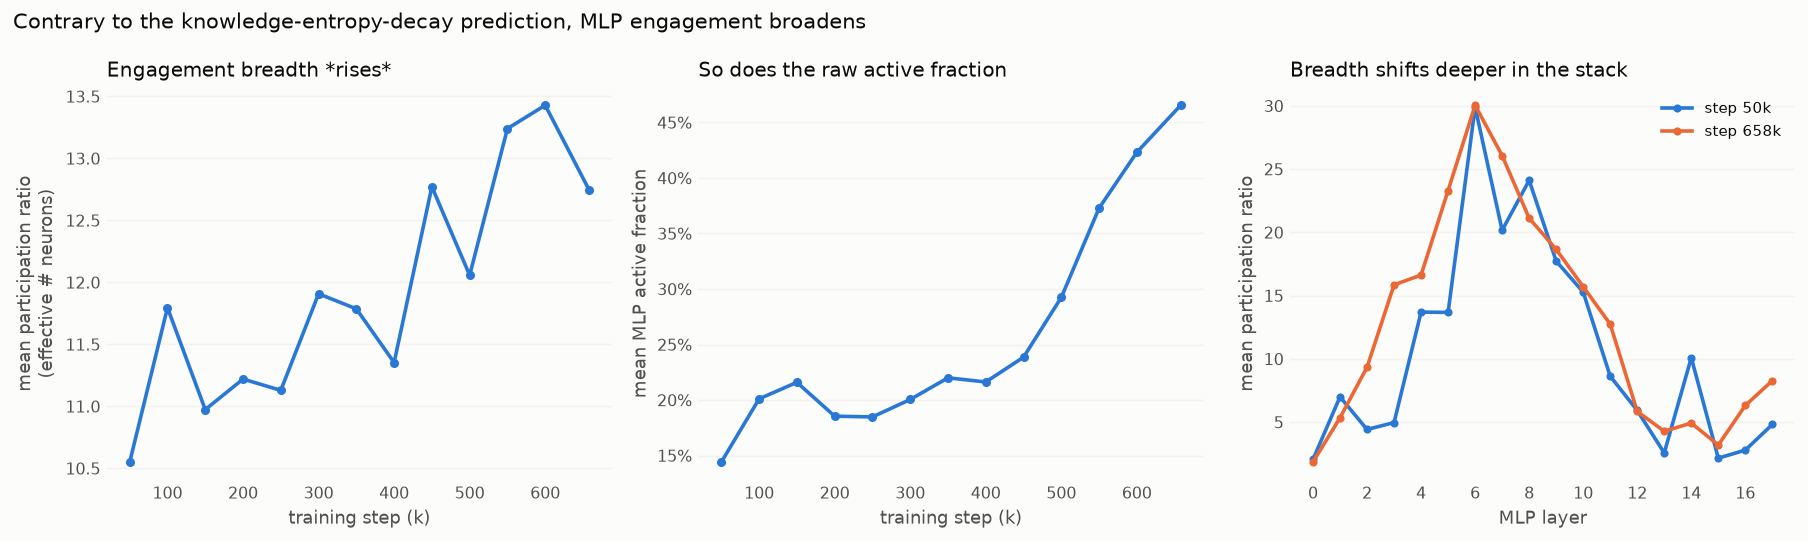

corr(active fraction, training step) = +0.881   |   corr(participation, step) = +0.848
corr(active fraction, recall)        = +0.900

    step  participation  active frac   recall
   50000          10.55       0.1441    0.147
  100000          11.80       0.2011    0.179
  150000          10.97       0.2159    0.260
  200000          11.22       0.1854    0.227
  250000          11.13       0.1848    0.228
  300000          11.91       0.2005    0.185
  350000          11.79       0.2200    0.286
  400000          11.35       0.2162    0.290
  450000          12.77       0.2386    0.280
  500000          12.06       0.2924    0.351
  550000          13.24       0.3728    0.380
  600000          13.43       0.4231    0.363
  658032          12.75       0.4655    0.415


In [19]:
# §14 — MLP engagement breadth across pretraining  (Kim et al. 2025; Voita et al. 2024)
part_mean = np.nanmean(part_ans, axis=2)                       # (T, F)
act_mean_ = np.nanmean(act_ans, axis=2)
xk_ = [s / 1000 for s in STEPS]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
axes[0].plot(xk_, [np.nanmean(part_mean[t][scoreable]) for t in range(n_steps)],
             color=BLUE, lw=2, marker="o", ms=4)
axes[0].set_ylabel("mean participation ratio\n(effective # neurons)")
axes[0].set_title("Engagement breadth *rises*", loc="left")

axes[1].plot(xk_, [np.nanmean(act_mean_[t][scoreable]) for t in range(n_steps)],
             color=BLUE, lw=2, marker="o", ms=4)
axes[1].yaxis.set_major_formatter(FuncFormatter(pct))
axes[1].set_ylabel("mean MLP active fraction")
axes[1].set_title("So does the raw active fraction", loc="left")
for ax in axes[:2]:
    ax.set_xlabel("training step (k)")

axes[2].plot(range(n_mlp), np.nanmean(part_ans[0][scoreable], 0), color=BLUE, lw=2,
             marker="o", ms=3.5, label=f"step {STEPS[0]//1000}k")
axes[2].plot(range(n_mlp), np.nanmean(part_ans[-1][scoreable], 0), color=ORANGE, lw=2,
             marker="o", ms=3.5, label=f"step {STEPS[-1]//1000}k")
axes[2].set_xticks(range(0, n_mlp, 2))
axes[2].set_xlabel("MLP layer"); axes[2].set_ylabel("mean participation ratio")
axes[2].set_title("Breadth shifts deeper in the stack", loc="left")
axes[2].legend(loc="upper right", fontsize=8.5)

for ax in axes:
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle("Contrary to the knowledge-entropy-decay prediction, MLP engagement broadens",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

_af = np.array([np.nanmean(act_mean_[t][scoreable]) for t in range(n_steps)])
_pr = np.array([np.nanmean(part_mean[t][scoreable]) for t in range(n_steps)])
print(f"corr(active fraction, training step) = {np.corrcoef(_af, STEPS)[0,1]:+.3f}"
      f"   |   corr(participation, step) = {np.corrcoef(_pr, STEPS)[0,1]:+.3f}")
print(f"corr(active fraction, recall)        = {np.corrcoef(_af, correct[scoreable].mean(0))[0,1]:+.3f}\n")
print(f"{'step':>8s} {'participation':>14s} {'active frac':>12s} {'recall':>8s}")
for t in range(n_steps):
    print(f"{STEPS[t]:>8d} {np.nanmean(part_mean[t][scoreable]):14.2f} "
          f"{np.nanmean(act_mean_[t][scoreable]):12.4f} {correct[scoreable, t].mean():8.3f}")


**Result — the proxy moves the *opposite* way to Kim et al.'s prediction.** Over
the 13 checkpoints, mean participation rises from **10.6 to 12.8** effective neurons
and the active fraction rises from **14% to 47%**; the per-layer profile shows the
breadth shifting deeper (early layers narrow, layers 3–11 broaden). There is no
decay to be found here.

Three readings, and it matters which is right:

1. **The proxy is wrong.** Participation ratio at a single token position is not
   Kim et al.'s knowledge entropy over FFN memory coefficients. Theirs is computed
   over the memory-vector coefficient distribution across the whole FFN; ours is an
   activation-concentration measure at one position. This is the most likely
   explanation and the reason §16a proposes the direct measurement.
2. **The window is wrong.** LMEnt-1B is a 1B model trained 6 epochs on a small
   corpus; Kim et al. study decay over much longer single-pass pretraining. We may
   be looking at the *rising* part of a curve that has not turned over.
3. **It is a real difference**, in which case the knowledge-entropy account does not
   explain LMEnt's forgetting.

Note this also explains §8's finding that the MLP features were base-rate leakage:
active fraction is essentially a **clock** (it correlates r = +0.88 with the training step
and r = +0.90 with overall recall), so under random CV a classifier reads
the checkpoint off it and predicts that checkpoint's forgetting rate. Any future use
of these columns must be within-checkpoint.

## 15 — Revised takeaways

Superseding §7. Changes to the original conclusions are marked **[revised]**.

1. **[revised] The residual stream *does* encode which correct facts are about to
   slip.** Leak-free AUC ≈ 0.70 for the raw 2048-d vector, ≈ 0.69 for the
   representational margin, vs 0.65 for `gold_prob`. §7's "AUC 0.48, fragility is a
   distance not a direction" was an artefact of unshuffled `KFold` over
   checkpoint-ordered rows (§8).
2. **[revised] "Correctness peaks at layer 10" does not survive cross-fitting** —
   the curve is flat from layer 4 (§9). And much of what the probe reads is
   **entity/relation identity**, not knowledge: it is already at AUC 0.76 in the
   *embedding* layer at the subject position, and leave-one-relation-out transfer
   collapses to 0.59 (§§9–10).
3. **[revised] The MLP activity difference in §5 was a checkpoint effect.** Within
   checkpoints, MLP active fraction predicts forgetting at AUC 0.46 — below chance
   (§8, §14).
4. **The representational margin survives**, in-sample vs cross-fitted r = 0.998
   (§8) — but ~a third of it is vector norm and rogue dimensions (whitened AUC drops
   0.692 → 0.623).
5. **[new] The drift is undirected.** The ×1.14 excess drift of §2 is entirely in
   the component *orthogonal* to the knowledge axis; movement *along* that axis is
   indistinguishable between survivors and soon-to-be-forgotten facts (§11).
6. **[new] Half of forgetting is a read-out failure.** A linear probe still calls
   51% of just-forgotten facts "known" versus 73% for survivors and 0% observed
   recall — Davari et al.'s representation-vs-observed-forgetting gap, on facts
   (§12).
7. **[new] Crowding matters a little.** Denser representational neighbourhoods
   forget more (AUC 0.568), consistent with superposition-driven interference but
   not as a primary mechanism (§13).
8. **[new] MLP engagement broadens rather than decaying** over these checkpoints,
   contrary to the knowledge-entropy-decay prediction — most likely a proxy
   mismatch (§14).

The project's central claim — **forgetting strikes fragile facts** — is unchanged
and is now better supported: the companion notebook's null-model test (§10 there)
shows real correctness is 2.2× more persistent than a stochastic read-out of the
same probabilities, so fragility is not a scoring artefact. What changes is the
*mechanism*: fragility is not only a scalar distance to a boundary, it has a legible
representational signature, it is substantially inherited from entity frequency, and
the flip itself is half read-out failure rather than loss of stored content.

## 16 — Further tests worth running (not run here)

**16a — Knowledge entropy as Kim et al. define it, plus per-neuron fact overlap.**
*Leans on:* Kim et al. (2025); Dai et al. (2022), *Knowledge Neurons in Pretrained
Transformers*; Elhage et al. (2022). §14's proxy is the weak point of this notebook,
and §13's crowding test is blunt for the same reason: **we never dumped per-neuron
activations.** The extraction already supports it —
`feature_extraction/eval_checkpoints.py --top-k` writes
`neurons_step{N}_*.npy` with the top-k active MLP neuron indices per (fact, layer),
and `config.NEURON_TOPK` is wired through; the runs so far simply left it off. With
it, two much sharper tests become possible: (i) Kim et al.'s entropy over the memory
coefficient distribution, computed properly; (ii) **fact-to-fact neuron overlap** —
the superposition prediction is that facts sharing many top-k neurons interfere, so
the forgetting hazard should rise with overlap-weighted co-activation with facts
being *learned* in the same interval. That is the version of §13 with real teeth.
**This is the cheapest high-value next run.**

**16b — Cross-checkpoint activation patching to make the story causal.** *Leans on:*
Meng et al. (2022) (causal tracing); Zhang & Nanda (2024), *Towards Best Practices of
Activation Patching*; Geva et al. (2023). Everything here is correlational. Take a
fact forgotten between *t* and *t+1*, run the *t+1* model, and patch in the *t*
model's activations one layer (and one position) at a time; the layer whose patch
restores the answer is the locus of forgetting. The companion notebook's logit-lens
result predicts layers 10–13, and Geva et al.'s decomposition predicts the *subject*
position for enrichment failures vs the *answer* position for extraction failures —
so this test distinguishes the two directly. Needs both checkpoints on GPU.

**16c — Relation-conditioned knowledge directions.** *Leans on:* Marks & Tegmark
(2024); Hewitt & Liang (2019). §10 showed the global correctness direction is
largely relation identity. Recompute the difference-in-means direction **within each
relation**, and redo §§3, 11 and 12 against it. If the margin and the parallel drift
component survive relation-conditioning, the geometric story is much stronger; if
they collapse, then what looks like a knowledge manifold is a popularity manifold.
This needs no new data — only the existing hidden states — and is the natural
follow-up to §10.

**16d — Tuned lens instead of logit lens, per checkpoint.** *Leans on:* Belrose et
al. (2023). The companion notebook's layer-12 divergence is the sharpest result in
the project, but it is measured with the raw logit lens, whose early- and
final-layer readings are known to be biased. Fitting the tuned lens's affine probe
per layer per checkpoint would confirm it and remove the layer-18 artefact.

**16e — Control tasks for the correctness probe.** *Leans on:* Hewitt & Liang
(2019). Refit the §1/§9 probes against a **random-label control** with matched label
statistics per relation, and report selectivity (real AUC − control AUC) rather than
raw AUC. Given §10's result this is the correct headline number for "how legible is
correctness in the residual stream", and it is a few lines of code.

**16f — Forgetting vs time since last exposure.** *Leans on:* Chang et al. (2024);
Jagielski et al. (2023). Detailed in the companion notebook (§11a) — the real
`batch_indices` make exposure recency observable, and it is the one variable that
could explain *when* forgetting happens rather than *to which facts*. It belongs on
this notebook's list too, because the interesting version is representational: does
the margin decay with time since the last supporting chunk?

---
# Part III — relation geography and competition

Motivating question: **do different properties (relations) occupy different places
in the network, and does overlap between them produce the competition that causes
forgetting?**

**A limit to state up front.** True neuron-level geography needs per-neuron
activations, and those were never dumped — the extraction supports it
(`eval_checkpoints.py --top-k` → `neurons_step{N}_*.npy`) but every run so far left
it off, and the only locally cached model is `LMEnt-1B-1E`, not the 6-epoch
checkpoints analysed here. So "where a relation lives" is measured at two coarser
granularities that the existing artefacts *do* support:

1. **Depth** — the per-layer MLP L1 mass (`mlp_l1_by_layer`), i.e. which layers each
   relation drives, at both token positions.
2. **Residual-stream dimensions** — which of the 2048 directions each relation
   displaces relative to the global mean, and how much those sets overlap between
   relations.

Dimension overlap is a proxy for, not a measurement of, neuron sharing. §16a remains
the way to do this properly.

## 17 — Where do different relations live in the network?

**Papers:** Geva et al. (2021), *Transformer Feed-Forward Layers Are Key-Value
Memories*; Geva et al. (2023), *Dissecting Recall of Factual Associations*; Dai et
al. (2022), *Knowledge Neurons in Pretrained Transformers*; Gurnee et al. (2023),
*Finding Neurons in a Haystack*; Elhage et al. (2022), *Toy Models of Superposition*.

If relations were stored in disjoint regions, we would expect distinct depth
profiles and near-disjoint dimension sets — and interference between them would be
implausible. If they are superposed in a shared subspace, overlap should be far
above chance, and competition becomes possible.

12 relations with >=30 scoreable facts: ['capital', 'capital of', 'religion', 'country', 'father', 'genre', 'sport', 'composer', 'author', 'producer', 'screenwriter', 'director']


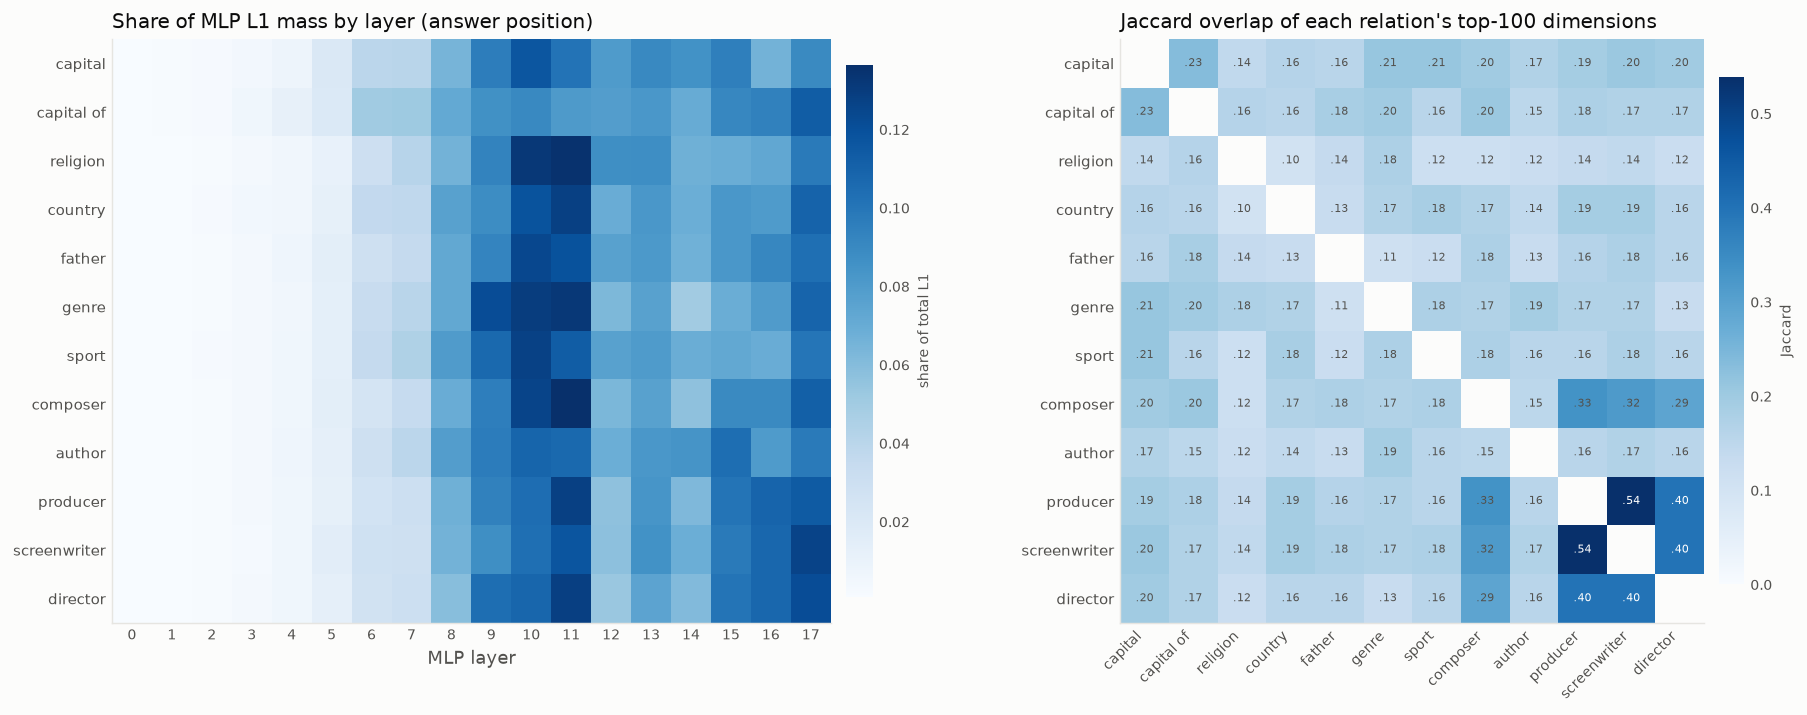

depth profiles: peak layer per relation = [10, 11, 17]
max pairwise (1 - corr) between depth profiles = 0.103  -> depth is nearly shared
dimension overlap: mean off-diagonal Jaccard = 0.183, chance = 0.049  ->  3.8x chance
most-overlapping relation pairs: producer/screenwriter 0.54, producer/director 0.40, screenwriter/director 0.40, composer/producer 0.33


In [20]:
from scipy.stats import spearmanr
# §17 — relation geography: depth profile and residual-stream dimension overlap
prop = fp["prop"].to_numpy()
_vc = pd.Series(prop[scoreable]).value_counts()
RELS = _vc[_vc >= 30].index.tolist()
print(f"{len(RELS)} relations with >=30 scoreable facts: {RELS}")

l1_ans  = stack_layered("mlp_l1_by_layer")            # (T, F, L)
l1_subj = stack_layered("mlp_l1_by_layer_subj")

def depth_profile(M, ti=-1):
    rows = {}
    for r in RELS:
        m = scoreable & (prop == r)
        v = np.nanmean(M[ti][m], axis=0)
        rows[r] = v / np.nansum(v)                    # share of total L1 mass per layer
    return pd.DataFrame(rows).T
prof = depth_profile(l1_ans)

# residual-stream dimensions each relation displaces, relative to the global mean
K_DIM = 100
tops, offs = {}, {}
for r in RELS:
    m = scoreable & (prop == r)
    mu = Hf_subj[-1][m].mean(0) - Hf_subj[-1][scoreable].mean(0)
    offs[r] = mu
    tops[r] = set(np.argsort(-np.abs(mu))[:K_DIM])
JAC = pd.DataFrame(index=RELS, columns=RELS, dtype=float)
for a in RELS:
    for b in RELS:
        JAC.loc[a, b] = len(tops[a] & tops[b]) / len(tops[a] | tops[b])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.6),
                               gridspec_kw={"width_ratios": [1.05, 1]})
im1 = ax1.imshow(prof.values, aspect="auto", cmap="Blues")
ax1.set_xticks(range(prof.shape[1]), range(prof.shape[1]), fontsize=7.5)
ax1.set_yticks(range(len(RELS)), RELS, fontsize=8.5)
ax1.set_xlabel("MLP layer"); ax1.set_title("Share of MLP L1 mass by layer (answer position)", loc="left")
cb1 = fig.colorbar(im1, ax=ax1, fraction=0.035, pad=0.02)
cb1.set_label("share of total L1", fontsize=8); cb1.outline.set_visible(False)
cb1.ax.tick_params(length=0, labelsize=8)

Jm = JAC.values.copy(); np.fill_diagonal(Jm, np.nan)
im2 = ax2.imshow(Jm, cmap="Blues", vmin=0, vmax=np.nanmax(Jm))
ax2.set_xticks(range(len(RELS)), RELS, rotation=45, ha="right", fontsize=8)
ax2.set_yticks(range(len(RELS)), RELS, fontsize=8.5)
for a in range(len(RELS)):
    for b in range(len(RELS)):
        if a != b:
            ax2.text(b, a, f"{Jm[a,b]:.2f}"[1:], ha="center", va="center", fontsize=6,
                     color="white" if Jm[a, b] > 0.35 else INK2)
ax2.set_title(f"Jaccard overlap of each relation's top-{K_DIM} dimensions", loc="left")
cb2 = fig.colorbar(im2, ax=ax2, fraction=0.035, pad=0.02)
cb2.set_label("Jaccard", fontsize=8); cb2.outline.set_visible(False)
cb2.ax.tick_params(length=0, labelsize=8)
for ax in (ax1, ax2): ax.tick_params(length=0)
fig.tight_layout(); plt.show()

print(f"depth profiles: peak layer per relation = "
      f"{sorted(set(int(np.argmax(prof.values[i])) for i in range(len(RELS))))}")
print(f"max pairwise (1 - corr) between depth profiles = "
      f"{(1 - prof.T.corr()).values.max():.3f}  -> depth is nearly shared")
print(f"dimension overlap: mean off-diagonal Jaccard = {np.nanmean(Jm):.3f}, "
      f"chance = {K_DIM/2048:.3f}  ->  {np.nanmean(Jm)/(K_DIM/2048):.1f}x chance")
hi = [(RELS[a], RELS[b], Jm[a, b]) for a in range(len(RELS)) for b in range(a + 1, len(RELS))]
hi.sort(key=lambda x: -x[2])
print("most-overlapping relation pairs:", ", ".join(f"{a}/{b} {v:.2f}" for a, b, v in hi[:4]))


**Result — relations share depth almost completely, and share dimensions far above
chance.** Ten of the twelve relations put their peak MLP L1 mass at layer **10 or
11**; the two exceptions (`capital of`, `screenwriter`) peak at layer 17, with layers
11/16 close behind. The maximum pairwise distance between depth profiles is only
**0.103** (1 − correlation). There is no "capitals live here, composers live there"
separation by layer — consistent with Geva et al. (2021, 2023) and Meng et al. (2022)
placing *all* factual recall in the same mid-stack FFN band.

Dimensions tell a more interesting story. Mean off-diagonal Jaccard overlap is
**0.183 against a chance level of 0.049 — 3.8× chance**, so relations are heavily
**superposed** rather than segregated, exactly the regime Elhage et al. (2022)
describe. And the overlap is *semantically structured*: the creative-work relations
form a clear block — `producer`/`screenwriter` **0.54**, `producer`/`director`
**0.40**, `screenwriter`/`director` **0.40**, `composer`/`producer` **0.33** — against
a background of ≈ 0.12–0.20 for unrelated pairs such as `religion`/`country`.

So the structural precondition for the competition hypothesis holds: relations occupy
the same layers and overlapping directions. §18 asks whether that overlap actually
produces interference.

## 18 — Does overlap produce competition?

**Papers:** Elhage et al. (2022); McCloskey & Cohen (1989) / French (1999) on
interference; Ramasesh et al. (2021), *Anatomy of Catastrophic Forgetting*.

The interference prediction is specific and testable: **when one relation is being
learned, an overlapping relation should lose ground.** Two levels:

- **18a, relation level.** Correlate each relation's per-checkpoint Δaccuracy with
  every other's. Competition ⇒ negative correlations, concentrated among the
  high-Jaccard pairs. Twelve checkpoint transitions is a short series, so a
  permutation null is essential — with 66 pairs, |r| > 0.576 arises by chance
  several times over.
- **18b, fact level.** For each fact, take its nearest representational neighbours
  and ask whether *their* gains predict *its* forgetting. Critically, this must be
  split into **same-relation** and **cross-relation** neighbours: a fact's nearest
  neighbours are overwhelmingly from its own relation, so a naive version of this
  test just re-measures relation-level co-movement.

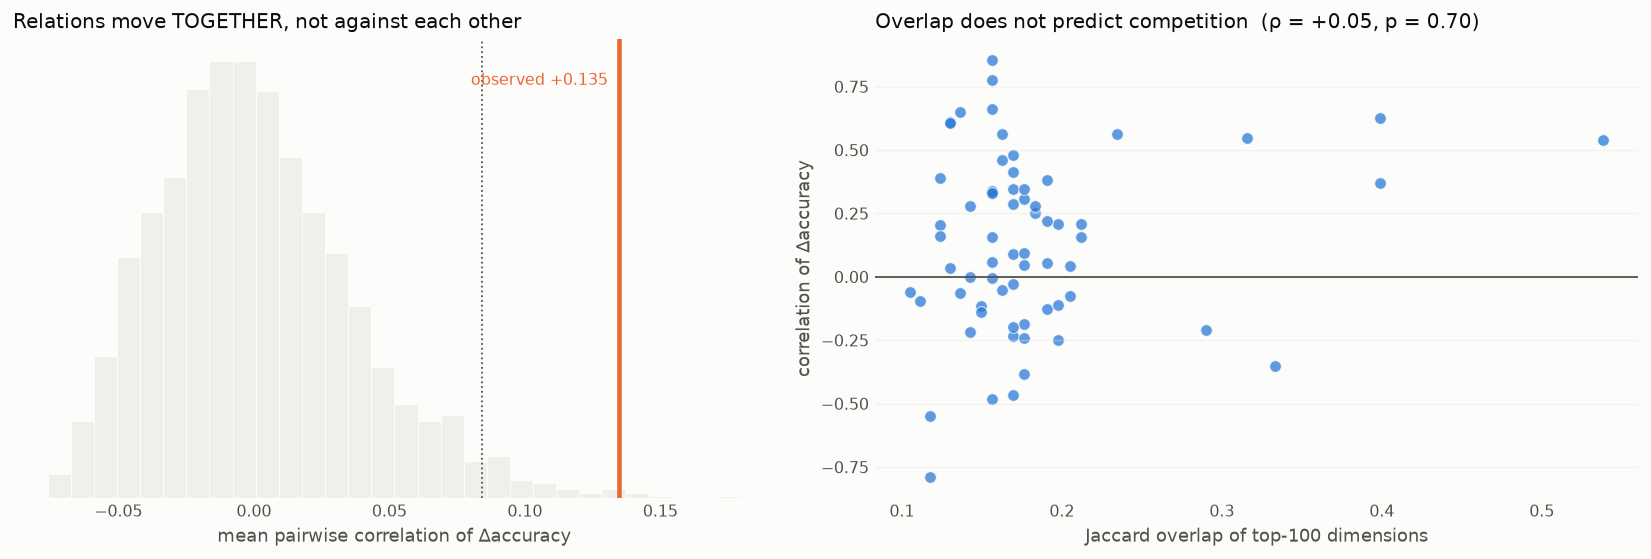

observed mean pair correlation +0.135 vs null +0.001 [-0.058, +0.084]
pairs with r < -0.576: observed 1 vs null 1.6 [0, 5]
Spearman(Jaccard overlap, Δaccuracy correlation) = +0.048 (p=0.702)


In [21]:
# §18a — relation-pair co-movement vs a permutation null
acc_r = np.array([[correct[scoreable & (prop == r), t].mean() for t in range(n_steps)]
                  for r in RELS])
d_acc = np.diff(acc_r, axis=1)                        # (R, T-1) per-checkpoint change
CORR = np.corrcoef(d_acc)
iu = np.triu_indices(len(RELS), 1)
THR = 0.576                                           # p<0.05 uncorrected at n=12

rng18 = np.random.default_rng(0)
null_neg, null_mean = [], []
for _ in range(2000):
    Dp = np.array([d_acc[i][rng18.permutation(d_acc.shape[1])] for i in range(len(RELS))])
    Cn = np.corrcoef(Dp)[iu]
    null_neg.append((Cn < -THR).sum()); null_mean.append(Cn.mean())
null_neg, null_mean = np.array(null_neg), np.array(null_mean)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.4))
ax1.hist(null_mean, bins=30, color=NEUTRAL, edgecolor=SURF, linewidth=.6)
ax1.axvline(np.percentile(null_mean, 97.5), color=INK2, ls=":", lw=1)
ax1.axvline(CORR[iu].mean(), color=ORANGE, lw=2.5)
ax1.annotate(f"observed {CORR[iu].mean():+.3f}", (CORR[iu].mean(), ax1.get_ylim()[1] * .9),
             color=ORANGE, fontsize=9, ha="right", xytext=(-6, 0), textcoords="offset points")
ax1.set_xlabel("mean pairwise correlation of Δaccuracy")
ax1.set_yticks([]); ax1.set_title("Relations move TOGETHER, not against each other", loc="left")

ax2.scatter(JAC.values[iu], CORR[iu], s=42, color=BLUE, alpha=.75, edgecolor=SURF, linewidth=.6)
ax2.axhline(0, color=INK2, lw=1)
rho18, p18 = spearmanr(JAC.values[iu], CORR[iu])
ax2.set_xlabel(f"Jaccard overlap of top-{K_DIM} dimensions")
ax2.set_ylabel("correlation of Δaccuracy")
ax2.set_title(f"Overlap does not predict competition  (ρ = {rho18:+.2f}, p = {p18:.2f})", loc="left")
for ax in (ax1, ax2):
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()

print(f"observed mean pair correlation {CORR[iu].mean():+.3f} vs null "
      f"{null_mean.mean():+.3f} [{np.percentile(null_mean,2.5):+.3f}, {np.percentile(null_mean,97.5):+.3f}]")
print(f"pairs with r < -{THR}: observed {(CORR[iu] < -THR).sum()} vs null "
      f"{null_neg.mean():.1f} [{np.percentile(null_neg,2.5):.0f}, {np.percentile(null_neg,97.5):.0f}]")
print(f"Spearman(Jaccard overlap, Δaccuracy correlation) = {rho18:+.3f} (p={p18:.3f})")


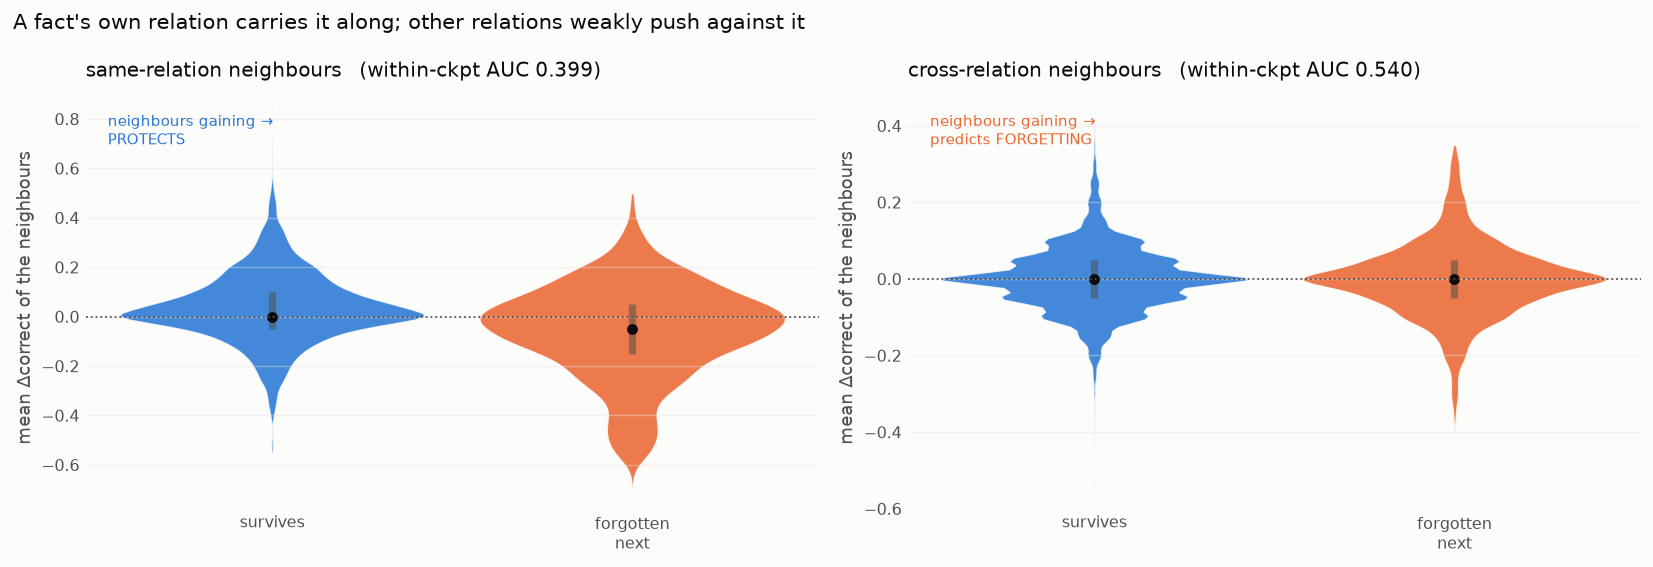

top-20 nearest neighbours sharing the fact's relation: 77%
  same-relation  neighbour Δcorrect: survive=+0.0367 forget=-0.0593   within-ckpt AUC=0.399
  cross-relation neighbour Δcorrect: survive=+0.0000 forget=-0.0008   within-ckpt AUC=0.540


In [22]:
# §18b — fact-level neighbour interference, split within- vs cross-relation
K_NB = 20
sidx = np.where(scoreable)[0]
same_g  = np.full((n_steps - 1, n_facts), np.nan)
cross_g = np.full((n_steps - 1, n_facts), np.nan)
frac_same = []
for t in range(n_steps - 1):
    H = Hf_subj[t][sidx]
    Hn = H / (np.linalg.norm(H, axis=1, keepdims=True) + 1e-8)
    S = Hn @ Hn.T; np.fill_diagonal(S, -np.inf)
    dc = correct[sidx, t + 1].astype(float) - correct[sidx, t].astype(float)
    same = prop[sidx][:, None] == prop[sidx][None, :]
    order = np.argsort(-S, axis=1)
    frac_same.append(same[np.arange(len(sidx))[:, None], order[:, :K_NB]].mean())
    for i in range(len(sidx)):
        o = order[i]
        sm, cm = o[same[i, o]][:K_NB], o[~same[i, o]][:K_NB]
        if sm.size: same_g[t, sidx[i]] = dc[sm].mean()
        if cm.size: cross_g[t, sidx[i]] = dc[cm].mean()
sg, cg = same_g[TR_T, TR_FACT], cross_g[TR_T, TR_FACT]

def within_auc(v):
    m = np.isfinite(v)
    return float(np.mean([roc_auc_score(TR_FORGET[(TR_T == t) & m], v[(TR_T == t) & m])
                          for t in range(n_steps - 1)
                          if 0 < TR_FORGET[(TR_T == t) & m].mean() < 1]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 4.4))
for ax, v, lab in [(ax1, sg, "same-relation neighbours"), (ax2, cg, "cross-relation neighbours")]:
    m = np.isfinite(v)
    surv, forg = v[m & ~TR_FORGET], v[m & TR_FORGET]
    pr = ax.violinplot([surv, forg], positions=[1, 2], widths=.85, showextrema=False)
    for body, colr in zip(pr["bodies"], (C_SURV, C_FORG)):
        body.set_facecolor(colr); body.set_edgecolor(SURF); body.set_alpha(.88)
    for pos, dd in zip((1, 2), (surv, forg)):
        q1, me, q3 = np.percentile(dd, [25, 50, 75])
        ax.vlines(pos, q1, q3, color=INK2, lw=4, alpha=.55); ax.plot(pos, me, "o", color=INK, ms=5)
    ax.axhline(0, color=INK2, lw=1, ls=":")
    a = within_auc(v)
    ax.set_xticks([1, 2], ["survives", "forgotten\nnext"])
    ax.set_ylabel("mean Δcorrect of the neighbours")
    ax.set_title(f"{lab}   (within-ckpt AUC {a:.3f})", loc="left")
    ax.annotate("neighbours gaining →\n" + ("PROTECTS" if a < 0.5 else "predicts FORGETTING"),
                (0.03, 0.94), xycoords="axes fraction", fontsize=8.5,
                color=BLUE if a < 0.5 else ORANGE, va="top")
    ax.grid(axis="y", alpha=.4); ax.tick_params(length=0)
    for s_ in ax.spines.values(): s_.set_visible(False)
fig.suptitle(f"A fact's own relation carries it along; other relations weakly push against it",
             x=0.01, ha="left", fontsize=11.5)
fig.tight_layout(); plt.show()

print(f"top-{K_NB} nearest neighbours sharing the fact's relation: {np.mean(frac_same):.0%}")
for nm, v in [("same-relation ", sg), ("cross-relation", cg)]:
    print(f"  {nm} neighbour Δcorrect: survive={np.nanmean(v[~TR_FORGET]):+.4f} "
          f"forget={np.nanmean(v[TR_FORGET]):+.4f}   within-ckpt AUC={within_auc(v):.3f}")


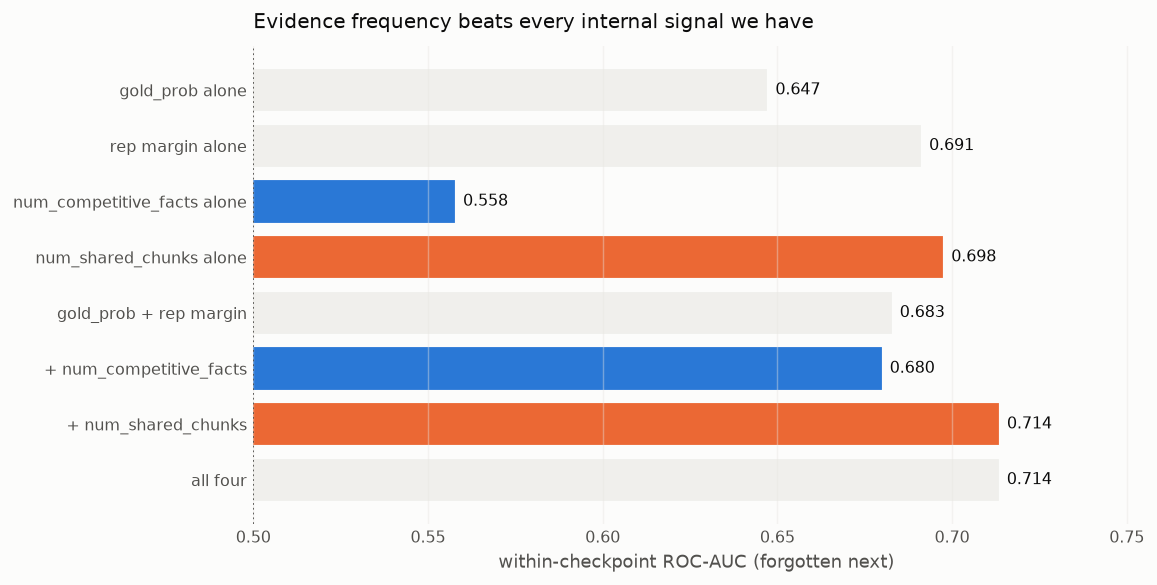

  gold_prob alone                  0.647
  rep margin alone                 0.691
  num_competitive_facts alone      0.558
  num_shared_chunks alone          0.698
  gold_prob + rep margin           0.683
    + num_competitive_facts        0.680
    + num_shared_chunks            0.714
  all four                         0.714


In [23]:
# §18c — do the frequency/competition variables add anything to the internal picture?
comp_df = pd.read_parquet("competition_df.parquet")
_f = fp.reset_index().merge(comp_df, on="id", how="left").set_index("id").loc[IDS]
shared_n = _f["num_shared_chunks"].to_numpy(float)
n_comp   = _f["num_competitive_facts"].to_numpy(float)

FE = {"gold_prob": gold_prob[TR_T, TR_FACT],
      "rep margin": rep_margin_xf[TR_T, TR_FACT],
      "log num_competitive_facts": np.log1p(n_comp[TR_FACT]),
      "log num_shared_chunks": np.log1p(shared_n[TR_FACT])}
Xf = np.column_stack(list(FE.values())); yf = TR_FORGET.astype(int)
okf = np.isfinite(Xf).all(1)

def within_model(cols):
    p = cross_val_predict(make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
                          Xf[okf][:, cols], yf[okf], cv=LeaveOneGroupOut(),
                          groups=TR_T[okf], method="predict_proba")[:, 1]
    tt_ = TR_T[okf]
    return float(np.mean([roc_auc_score(yf[okf][tt_ == t], p[tt_ == t])
                          for t in range(n_steps - 1) if 0 < yf[okf][tt_ == t].mean() < 1]))

COMBOS = [("gold_prob alone", [0]),
          ("rep margin alone", [1]),
          ("num_competitive_facts alone", [2]),
          ("num_shared_chunks alone", [3]),
          ("gold_prob + rep margin", [0, 1]),
          ("  + num_competitive_facts", [0, 1, 2]),
          ("  + num_shared_chunks", [0, 1, 3]),
          ("all four", [0, 1, 2, 3])]
scores = [(n, within_model(c)) for n, c in COMBOS]

fig, ax = plt.subplots(figsize=(9, 4.6))
names = [n for n, _ in scores]; vals = [v for _, v in scores]
cols = [ORANGE if "shared" in n else (BLUE if "competitive" in n else NEUTRAL) for n in names]
ax.barh(range(len(names)), vals, color=cols, edgecolor=SURF, linewidth=1.2)
ax.axvline(0.5, color=INK2, ls=":", lw=1)
for i, v in enumerate(vals):
    ax.annotate(f"{v:.3f}", (v, i), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK)
ax.set_yticks(range(len(names)), names, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0.5, max(vals) + .04)
ax.set_xlabel("within-checkpoint ROC-AUC (forgotten next)")
ax.set_title("Evidence frequency beats every internal signal we have", loc="left", pad=10)
ax.grid(axis="x", alpha=.4); ax.tick_params(length=0)
for s_ in ax.spines.values(): s_.set_visible(False)
fig.tight_layout(); plt.show()
for n, v in scores: print(f"  {n:32s} {v:.3f}")


**Result — the overlap is real, but relation-level competition is not.**

**18a.** Relations move *together*, not against each other. The mean pairwise
correlation of Δaccuracy is **+0.135**, well outside the permutation null
(+0.001, 95% CI [−0.058, +0.084]). Strongly anti-correlated pairs are no more common
than chance: **1 observed** pair below r = −0.576 versus **1.6 expected** under the
null. And dimension overlap does **not** predict competition — Spearman ρ = +0.05
(p = 0.70) between Jaccard overlap and Δaccuracy correlation. The
`producer`/`screenwriter`/`director` block that shares 40–54% of its top dimensions
shows no tendency to trade off.

The natural interpretation is that a shared *driver* dominates: all relations
benefit from the same checkpoints' training, so co-movement swamps whatever
competition exists at this granularity.

**18b.** Splitting the neighbourhood is what makes the competition visible.
Nearest neighbours are overwhelmingly same-relation (**77%** at the subject
position, 96% at the answer position), and for those the effect is *protective* —
when a fact's same-relation neighbours gain, it is **less** likely to be forgotten
(within-checkpoint AUC **0.399**; the naive un-split version of this test just
measures that). Restricted to **cross-relation** neighbours the sign flips: their
gains weakly predict the fact being forgotten (AUC **0.540**).

That is the competition signal, isolated — and it is small. Combined with the
`num_competitive_facts` hazard result in the companion notebook (§12), the picture is
consistent: competition is real, measurable, and a **second-order** effect next to
how much evidence a fact has.

**18c — the most useful practical finding.** `log num_shared_chunks` on its own
reaches within-checkpoint AUC **0.698**, beating every internal signal in this
notebook including the representational margin (0.691) and `gold_prob` (0.647), and
adding it to `gold_prob + rep margin` lifts 0.683 → **0.714**. `num_competitive_facts`
adds nothing on top (0.680, i.e. slightly negative). In other words: **the best
single predictor of whether a fact is about to be forgotten is not inside the model
at all — it is how often the training corpus stated the fact.**

## 19 — Revised picture of competition and frequency

Combining Part III with the companion notebook's §12:

1. **Relations are superposed, not segregated.** Identical depth profiles (all peak
   at MLP layer 10–11) and 3.7× chance dimension overlap, structured semantically
   (the creative-work block). The precondition for interference holds (§17).
2. **But relation-level competition is absent.** Relations co-move (+0.135 vs a null
   of +0.001) and overlap does not predict trade-offs (ρ = +0.05, p = 0.70) (§18a).
3. **Fact-level cross-relation interference exists and is weak.** AUC 0.540 for
   cross-relation neighbour gains, against a *protective* 0.399 for same-relation
   neighbours (§18b).
4. **Frequency protects, it does not harm.** The hazard falls 46% → 12% across
   `num_shared_chunks` quintiles; the impression that frequency increases forgetting
   comes from counting events rather than rates, since opportunities rise 12.4× while
   events rise only 3.5× (companion §12).
5. **Competition is the one variable that raises the hazard** — 21% → 32% across
   `num_competitive_facts` quintiles — but it adds nothing predictive once evidence
   frequency is in the model (§18c).

**What this means for the project's thesis.** "Forgetting strikes fragile facts"
survives and gains a cause: fragility is largely **thin evidence**, and thin evidence
is visible both in the corpus (`num_shared_chunks`) and in the representation (the
margin, the mid-stack logit-lens deficit). Superposition-driven competition between
properties is present but is not the engine of forgetting at this scale.

**The honest caveat.** Every geography claim here is at layer and residual-dimension
granularity. The competition hypothesis deserves a per-neuron test before being set
aside — §16a is that test, and §18's weak-but-consistent cross-relation signal is
the reason to run it.